# 01 - Analisis Dataset (EDA Awal)

Tujuan: memahami karakteristik dataset di `data/raw/` sebelum preprocessing dan training.

**Batasan tahap ini.** Notebook hanya *membaca* berkas citra. Tidak ada training, augmentasi, resize atau normalisasi permanen, split baru, perubahan label, pemindahan, atau penghapusan berkas. Keluaran hanya ditulis ke `reports/`.

**Menjalankan ulang.** Jalankan semua sel dari atas ke bawah. Hasil pemindaian per citra disimpan di `reports/tables/` dan dipakai ulang selama daftar berkas dataset tidak berubah; set `FORCE_RECOMPUTE = True` untuk menghitung ulang semuanya.

**Kode yang dipakai ulang.** Pemeriksaan berkas, hash, dan dHash memakai `scripts/audit_dataset.py`; statistik per citra memakai `src/datasets/image_stats.py`; histogram RGB memakai `src/datasets/pixel_histogram.py`.

## 1. Import dan Environment

In [1]:
import os
import platform
import sys
import time
from concurrent.futures import ProcessPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from IPython.display import Markdown, display
from PIL import Image

T0 = time.time()
print("Python      :", sys.version.split()[0], "|", platform.platform())
for name, module in [("numpy", np), ("pandas", pd), ("matplotlib", matplotlib), ("Pillow", PIL)]:
    print(f"{name:12s}:", module.__version__)

# PyTorch hanya dipakai untuk melaporkan device; EDA ini tidak memakai GPU.
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"{'torch':12s}:", torch.__version__)
    print(f"{'Device':12s}:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")
except ImportError:
    DEVICE = "cpu"
    print(f"{'Device':12s}: cpu (PyTorch tidak terpasang di environment ini)")
print(f"{'CPU logis':12s}:", os.cpu_count())

Python      : 3.11.9 | Windows-10-10.0.26200-SP0
numpy       : 1.26.2
pandas      : 2.1.3
matplotlib  : 3.8.2
Pillow      : 10.1.0
Device      : cpu (PyTorch tidak terpasang di environment ini)
CPU logis   : 16


In [2]:
SEED = 42                       # dipakai untuk semua pengambilan sampel visual
SAMPLES_PER_CLASS = 5
WORKERS = min(8, os.cpu_count() or 2)
FORCE_RECOMPUTE = False         # True: abaikan cache di reports/tables/ dan pindai ulang semua citra

# Ambang di bawah ini adalah konvensi notebook ini, bukan standar baku.
IMBALANCE_WARNING_RATIO = 3.0   # rasio kelas terbesar/terkecil mulai dari nilai ini berstatus Warning
NEAR_DUP_MAX_HAMMING = 10       # dari 256 bit dHash; sama dengan scripts/audit_dataset.py
HASH_BALANCE = (0.15, 0.85)     # dHash dianggap informatif bila bagian bit bernilai 1 ada di rentang ini
UNIFORM_MAX_CONTRAST = 0.01     # contrast (skala 0-1) di bawah ini dicatat sebagai citra hampir seragam
DARK_MAX_BRIGHTNESS = 0.10      # brightness di bawah ini dicatat sebagai citra sangat gelap
BRIGHT_MIN_BRIGHTNESS = 0.95    # brightness di atas ini dicatat sebagai citra sangat terang

SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val",
                 "validation": "val", "test": "test", "testing": "test"}
SPLIT_ORDER = ["train", "val", "test"]
SPLIT_LABEL = {"train": "Train", "val": "Validation", "test": "Test", "all": "Semua"}

def disp_splits(ds):
    """Urutan split untuk ditampilkan: SPLIT_ORDER untuk dataset standar
    (train/val/test), atau split dataset itu sendiri (mis. 'all') untuk
    dataset tanpa split."""
    s = R[ds]["splits"]
    return SPLIT_ORDER if set(s) <= set(SPLIT_ORDER) else s
EXT_FORMAT = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG", ".bmp": "BMP", ".gif": "GIF",
              ".tif": "TIFF", ".tiff": "TIFF", ".webp": "WEBP"}
CHANNELS = ["R", "G", "B"]
CHANNEL_NAME = {"R": "Red", "G": "Green", "B": "Blue"}
CHANNEL_COLOR = {"R": "#d1453b", "G": "#2e9e5b", "B": "#3b7dd8"}
BAR_COLOR = "#3b7dd8"

PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
RAW_DIR = PROJECT_DIR / "data" / "raw"
TABLE_DIR = PROJECT_DIR / "reports" / "tables"
FIG_DIR = PROJECT_DIR / "reports" / "figures" / "eda"
REPORT_PATH = PROJECT_DIR / "reports" / "EDA_INITIAL_REPORT.md"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from scripts.audit_dataset import FIELDS, IMAGE_EXTS, inspect
from src.datasets.image_stats import channel_mean_std, compute_stats
from src.datasets.pixel_histogram import histogram_stats, histograms_by_group

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 9})

# Catatan observasi visual: ditulis tangan setelah meninjau gambar bagian 6 dan 10 (seed 42).
# Bila SEED, SAMPLES_PER_CLASS, atau dataset berubah, gambar berubah dan catatan ini harus ditinjau ulang.
VISUAL_NOTES = {
    "GCD": {
        "near_duplicate": "Keenam pasangan lintas split yang ditampilkan (semuanya 4_clearsky, jarak Hamming 0 sampai 1) tampak sebagai citra yang sama, termasuk satu pasangan dengan silau matahari di posisi yang sama. Hash pikselnya berbeda, sehingga kemungkinan besar ini citra yang sama yang disimpan atau dikompresi ulang. Kandidat lain di tabel belum ditinjau.",
        "classes": {
            "1_cumulus": {
                "Karakteristik visual umum": "Gumpalan putih tebal bertepi tegas di atas langit biru pekat",
                "Variasi tampilan": "Cakupan awan dari sekitar sepertiga sampai hampir seluruh bingkai; satu sampel memiliki dasar awan abu-abu",
                "Kualitas citra": "Tajam; tidak terlihat noise atau artefak yang mengganggu",
                "Potensi overlap (kesan visual)": "7_mixed (salah satu sampel mixed tampak seperti cumulus)"
            },
            "2_altocumulus": {
                "Karakteristik visual umum": "Gumpalan kecil berulang yang menutupi hampir seluruh bingkai",
                "Variasi tampilan": "Dari tipis dan terang sampai tebal dengan celah gelap; satu sampel pucat dan berkontras rendah",
                "Kualitas citra": "Tajam; tidak terlihat noise atau artefak yang mengganggu",
                "Potensi overlap (kesan visual)": "7_mixed; sampel yang pucat mendekati lapisan awan rata"
            },
            "3_cirrus": {
                "Karakteristik visual umum": "Serat atau selubung tipis di atas langit biru",
                "Variasi tampilan": "Sangat lebar: dari serat jelas sampai dua sampel yang hampir tanpa struktur",
                "Kualitas citra": "Baik; awan sangat tipis sehingga detailnya samar",
                "Potensi overlap (kesan visual)": "4_clearsky dan 5_stratocumulus pada sampel yang hampir polos (mis. 3_cirrus_000576, 3_cirrus_000211)"
            },
            "4_clearsky": {
                "Karakteristik visual umum": "Biru polos atau gradasi halus, hampir tanpa tekstur",
                "Variasi tampilan": "Rona biru berbeda-beda; satu sampel kebiruan-ungu pucat",
                "Kualitas citra": "Baik; hampir tidak ada detail untuk dinilai",
                "Potensi overlap (kesan visual)": "3_cirrus yang sangat tipis"
            },
            "5_stratocumulus": {
                "Karakteristik visual umum": "Lapisan abu-abu atau biru pucat yang menutupi seluruh bingkai",
                "Variasi tampilan": "Tiga sampel abu-abu rata nyaris tanpa tekstur; dua sampel kebiruan dengan tekstur halus",
                "Kualitas citra": "Baik; kontras rendah",
                "Potensi overlap (kesan visual)": "6_cumulonimbus pada sampel bertekstur; langit pucat pada sampel rata"
            },
            "6_cumulonimbus": {
                "Karakteristik visual umum": "Lapisan tebal abu-biru bertekstur lembut yang menutupi seluruh bingkai",
                "Variasi tampilan": "Cukup seragam antar sampel; berbeda pada tingkat kegelapan",
                "Kualitas citra": "Baik; kontras rendah sampai sedang",
                "Potensi overlap (kesan visual)": "5_stratocumulus"
            },
            "7_mixed": {
                "Karakteristik visual umum": "Beberapa bentuk awan dalam satu bingkai",
                "Variasi tampilan": "Paling beragam; tiap sampel tampak berbeda satu sama lain",
                "Kualitas citra": "Tajam; tidak terlihat noise atau artefak yang mengganggu",
                "Potensi overlap (kesan visual)": "1_cumulus dan 2_altocumulus (mis. 7_mixed_000054 tampak seperti cumulus)"
            }
        }
    }
}

R = {}          # hasil per dataset
REPORT = []     # isi reports/EDA_INITIAL_REPORT.md, dikumpulkan sambil berjalan
CREATED = []    # berkas yang ditulis pada eksekusi ini


def fint(n):
    return f"{int(n):,}".replace(",", ".")


def fdec(x, d=2):
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def fmt(v, d=2):
    if v is None or v is pd.NA or (isinstance(v, (float, np.floating)) and np.isnan(v)):
        return "-"
    if isinstance(v, (bool, np.bool_)):
        return "Ya" if v else "Tidak"
    if isinstance(v, (int, np.integer)):
        return fint(v)
    if isinstance(v, (float, np.floating)):
        return fdec(v, d)
    return str(v).replace("|", "\\|")


def md_table(df, d=2):
    numeric = [pd.api.types.is_numeric_dtype(df[c]) for c in df.columns]
    lines = ["| " + " | ".join(str(c) for c in df.columns) + " |",
             "|" + "|".join("---:" if n else "---" for n in numeric) + "|"]
    lines += ["| " + " | ".join(fmt(v, d) for v in row) + " |" for row in df.itertuples(index=False, name=None)]
    return "\n".join(lines)


def say(text, report=True):
    """Tampilkan teks Markdown; bila report=True, teks ikut masuk ke laporan."""
    display(Markdown(text))
    if report:
        REPORT.append(text)


def show(df, d=2, report=True, max_rows=None):
    shown = df if max_rows is None else df.head(max_rows)
    text = md_table(shown, d)
    if max_rows is not None and len(df) > max_rows:
        text += f"\n\n*Menampilkan {fint(max_rows)} dari {fint(len(df))} baris.*"
    say(text, report)


def rel(path):
    return Path(path).relative_to(PROJECT_DIR).as_posix()


def prefix(ds):
    return f"{ds.lower()}_raw"


def table_path(ds, name):
    return TABLE_DIR / f"{prefix(ds)}_eda_{name}.csv"


def save_table(df, ds, name):
    path = table_path(ds, name)
    df.to_csv(path, index=False, encoding="utf-8")
    CREATED.append(path)
    return path


def save_fig(fig, ds, name):
    path = FIG_DIR / (f"{name}.png" if len(DATASETS) == 1 else f"{name}_{ds}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    CREATED.append(path)
    return path


print("Akar proyek :", PROJECT_DIR)
print("Sumber data :", rel(RAW_DIR))
print("Keluaran    :", rel(TABLE_DIR), "|", rel(FIG_DIR), "|", rel(REPORT_PATH))

Akar proyek : D:\n8n-logsiswaparalayang\Jurnal\CitraAwan
Sumber data : data/raw
Keluaran    : reports/tables | reports/figures/eda | reports/EDA_INITIAL_REPORT.md


## 2. Dataset Discovery

Setiap folder di `data/raw/` yang berisi citra dianggap satu dataset. Struktur yang diharapkan: `<dataset>/<split>/<kelas>/<citra>`. Nama folder split dipetakan ke `train`, `val`, atau `test`. Bila ada lebih dari satu dataset, masing-masing dianalisis terpisah dan tidak digabung.

In [3]:
def scan_files(root):
    """Inventaris semua berkas di bawah root tanpa membuka isinya."""
    rows = []
    for p in sorted(root.rglob("*")):
        if not p.is_file():
            continue
        parts = p.relative_to(root).parts
        split_dir = parts[0] if len(parts) >= 3 else ""
        rows.append({
            "split": SPLIT_ALIASES.get(split_dir.lower(), split_dir) or "all",
            "split_dir": split_dir,
            "class": parts[-2] if len(parts) >= 2 else "(tanpa kelas)",
            "filename": parts[-1],
            "rel_path": "/".join(parts),
            "bytes": p.stat().st_size,
            "ext": p.suffix.lower(),
        })
    files = pd.DataFrame(rows, columns=["split", "split_dir", "class", "filename", "rel_path", "bytes", "ext"])
    files["is_image"] = files["ext"].isin(IMAGE_EXTS)
    return files


print("Isi data/raw/:")
FILES = {}
for p in sorted(RAW_DIR.iterdir()):
    if p.is_dir():
        found = scan_files(p)
        print(f"  {p.name}/  (folder, {fint(len(found))} berkas)")
        if found["is_image"].any():
            FILES[p.name] = found
    else:
        print(f"  {p.name}  (berkas, {fint(p.stat().st_size)} byte; bukan folder dataset)")
DATASETS = list(FILES)
assert DATASETS, "Tidak ada dataset citra di data/raw/."

REPORT.append("# Laporan EDA Awal\n\nDihasilkan oleh `notebooks/01_dataset_analysis.ipynb` (seed "
              f"{SEED}) dari isi `data/raw/` apa adanya. Tidak ada berkas dataset yang diubah, dipindah, "
              "atau dihapus. Angka di laporan ini adalah hasil perhitungan, kecuali bagian yang "
              "ditandai sebagai observasi visual. Tabel lengkap ada di `reports/tables/` dan grafik di "
              "`reports/figures/eda/`.")
REPORT.append("## Dataset yang ditemukan")

rows = []
for ds in DATASETS:
    img = FILES[ds][FILES[ds]["is_image"]]
    classes = sorted(img["class"].unique())
    splits = [s for s in SPLIT_ORDER if (img["split"] == s).any()] + sorted(set(img["split"]) - set(SPLIT_ORDER))
    other_splits = sorted(set(img["split"]) - set(SPLIT_ORDER))
    per_split = {s: sorted(img.loc[img["split"] == s, "class"].unique()) for s in splits}
    R[ds] = {"classes": classes, "splits": splits, "root": RAW_DIR / ds,
             "class_consistent": all(v == classes for v in per_split.values())}
    print(f"\n{ds}/")
    for s in splits:
        part = img[img["split"] == s]
        print(f"  {part['split_dir'].iloc[0] or '.'}/  -> {part['class'].nunique()} folder kelas, {fint(len(part))} citra")
    folder = {s: (f"data/raw/{ds}/{img.loc[img['split'] == s, 'split_dir'].iloc[0]}" if s in splits else "tidak ada")
              for s in SPLIT_ORDER}
    rows.append({"Dataset": ds, "Folder train": folder["train"], "Folder validation": folder["val"],
                 "Folder test": folder["test"], "Jumlah kelas": len(classes),
                 "Nama kelas": ", ".join(classes), "Jumlah citra": len(img)})
    if other_splits:
        print(f"  Catatan: citra di luar train/val/test: {other_splits}")

discovery = pd.DataFrame(rows)
show(discovery)
for ds in DATASETS:
    status = "sama di semua split" if R[ds]["class_consistent"] else "BERBEDA antar split"
    missing = [SPLIT_LABEL[s] for s in SPLIT_ORDER if s not in R[ds]["splits"]]
    say(f"- **{ds}**: {len(R[ds]['classes'])} kelas; daftar folder kelas {status}."
        + (f" Split yang tidak tersedia: **{', '.join(missing)}**." if missing else ""))

Isi data/raw/:
  .gitkeep  (berkas, 0 byte; bukan folder dataset)


  CCSN_v2/  (folder, 2.543 berkas)


  GCD/  (folder, 19.000 berkas)
  GCD.zip  (berkas, 183.747.585 byte; bukan folder dataset)

CCSN_v2/
  ./  -> 11 folder kelas, 2.543 citra
  Catatan: citra di luar train/val/test: ['all']

GCD/
  train/  -> 7 folder kelas, 10.000 citra
  test/  -> 7 folder kelas, 9.000 citra


| Dataset | Folder train | Folder validation | Folder test | Jumlah kelas | Nama kelas | Jumlah citra |
|---|---|---|---|---:|---|---:|
| CCSN_v2 | tidak ada | tidak ada | tidak ada | 11 | Ac, As, Cb, Cc, Ci, Cs, Ct, Cu, Ns, Sc, St | 2.543 |
| GCD | data/raw/GCD/train | tidak ada | data/raw/GCD/test | 7 | 1_cumulus, 2_altocumulus, 3_cirrus, 4_clearsky, 5_stratocumulus, 6_cumulonimbus, 7_mixed | 19.000 |

- **CCSN_v2**: 11 kelas; daftar folder kelas sama di semua split. Split yang tidak tersedia: **Train, Validation, Test**.

- **GCD**: 7 kelas; daftar folder kelas sama di semua split. Split yang tidak tersedia: **Validation**.

## 3. Distribusi Data

Jumlah citra dihitung dari berkas berekstensi citra di setiap folder kelas. Split yang tidak tersedia ditulis 0.

In [4]:
for ds in DATASETS:
    img = FILES[ds][FILES[ds]["is_image"]]
    classes = R[ds]["classes"]
    tab = pd.crosstab(img["class"], img["split"]).reindex(index=classes, columns=disp_splits(ds), fill_value=0).astype(int)
    tab["Total"] = tab.sum(axis=1)
    out = tab.rename(columns=SPLIT_LABEL).rename_axis("Class").reset_index()
    out = pd.concat([out, pd.DataFrame([["Total", *tab.sum().tolist()]], columns=out.columns)], ignore_index=True)

    summary = []
    for col in disp_splits(ds) + ["Total"]:
        counts = tab[col]
        if counts.sum() == 0:
            continue
        summary.append({"Split": SPLIT_LABEL.get(col, "Semua split"), "Jumlah citra": int(counts.sum()),
                        "Kelas terbesar": counts.idxmax(), "n terbesar": int(counts.max()),
                        "Kelas terkecil": counts.idxmin(), "n terkecil": int(counts.min()),
                        "Rasio terbesar/terkecil": counts.max() / counts.min()})
    summary = pd.DataFrame(summary)
    R[ds]["dist"], R[ds]["imbalance"] = tab, summary

    say(f"## Distribusi data: {ds}")
    show(out)
    show(summary)
    save_table(out, ds, "class_distribution")

    for s in disp_splits(ds):
        if tab[s].sum() == 0:
            say(f"Split **{SPLIT_LABEL[s]}** tidak tersedia di `data/raw/{ds}/`; grafiknya tidak dibuat.", report=False)
            continue
        fig, ax = plt.subplots(figsize=(8, 3.8))
        bars = ax.bar(classes, tab[s], color=BAR_COLOR, width=0.62)
        for cls in {tab[s].idxmax(), tab[s].idxmin()}:   # label hanya pada kelas terbesar dan terkecil
            bar = bars[classes.index(cls)]
            ax.annotate(fint(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha="center", va="bottom", xytext=(0, 2), textcoords="offset points")
        ax.set_title(f"{ds}: distribusi kelas pada {SPLIT_LABEL[s]} (n = {fint(tab[s].sum())})", loc="left")
        ax.set_ylabel("Jumlah citra")
        ax.grid(axis="x", visible=False)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        save_fig(fig, ds, f"class_distribution_{s}")
        plt.show()

## Distribusi data: CCSN_v2

| Class | Semua | Total |
|---|---:|---:|
| Ac | 221 | 221 |
| As | 188 | 188 |
| Cb | 242 | 242 |
| Cc | 268 | 268 |
| Ci | 139 | 139 |
| Cs | 287 | 287 |
| Ct | 200 | 200 |
| Cu | 182 | 182 |
| Ns | 274 | 274 |
| Sc | 340 | 340 |
| St | 202 | 202 |
| Total | 2.543 | 2.543 |

| Split | Jumlah citra | Kelas terbesar | n terbesar | Kelas terkecil | n terkecil | Rasio terbesar/terkecil |
|---|---:|---|---:|---|---:|---:|
| Semua | 2.543 | Sc | 340 | Ci | 139 | 2,45 |
| Semua split | 2.543 | Sc | 340 | Ci | 139 | 2,45 |

<Figure size 880x418 with 1 Axes>

## Distribusi data: GCD

| Class | Train | Validation | Test | Total |
|---|---:|---:|---:|---:|
| 1_cumulus | 775 | 0 | 750 | 1.525 |
| 2_altocumulus | 725 | 0 | 750 | 1.475 |
| 3_cirrus | 1.153 | 0 | 753 | 1.906 |
| 4_clearsky | 2.150 | 0 | 1.589 | 3.739 |
| 5_stratocumulus | 1.846 | 0 | 1.790 | 3.636 |
| 6_cumulonimbus | 3.003 | 0 | 2.761 | 5.764 |
| 7_mixed | 348 | 0 | 607 | 955 |
| Total | 10.000 | 0 | 9.000 | 19.000 |

| Split | Jumlah citra | Kelas terbesar | n terbesar | Kelas terkecil | n terkecil | Rasio terbesar/terkecil |
|---|---:|---|---:|---|---:|---:|
| Train | 10.000 | 6_cumulonimbus | 3.003 | 7_mixed | 348 | 8,63 |
| Test | 9.000 | 6_cumulonimbus | 2.761 | 7_mixed | 607 | 4,55 |
| Semua split | 19.000 | 6_cumulonimbus | 5.764 | 7_mixed | 955 | 6,04 |

<Figure size 880x418 with 1 Axes>

Split **Validation** tidak tersedia di `data/raw/GCD/`; grafiknya tidak dibuat.

<Figure size 880x418 with 1 Axes>

## 4. Pemeriksaan File

Setiap citra dibuka dua kali oleh `scripts/audit_dataset.py::inspect`: verifikasi header, lalu decoding penuh untuk mendeteksi berkas terpotong. Hasil per citra (manifest) juga memuat SHA-256 isi berkas, hash piksel, dan dHash yang dipakai di bagian 10 dan 11. Berkas bermasalah hanya dicatat, tidak dihapus.

In [5]:
STR_COLS = ["sha256", "pixel_sha256", "dhash", "error", "format", "mode"]


def read_manifest(path):
    man = pd.read_csv(path, dtype={c: str for c in STR_COLS})
    man[STR_COLS] = man[STR_COLS].fillna("")
    man = man.rename(columns={"class_dir": "class"})
    man["split"] = man["split"].fillna("").map(lambda s: SPLIT_ALIASES.get(str(s).lower(), s) or "all")
    man["readable"] = man["readable"].astype(int)
    return man


def load_manifest(ds):
    """Pakai manifest hasil audit bila masih cocok dengan isi folder; jika tidak, pindai ulang."""
    path = TABLE_DIR / f"{prefix(ds)}_manifest.csv"
    img = FILES[ds][FILES[ds]["is_image"]]
    current = set(zip(img["rel_path"], img["bytes"]))
    if path.exists() and not FORCE_RECOMPUTE:
        man = read_manifest(path)
        if set(zip(man["rel_path"], man["bytes"])) == current:
            return man, f"dipakai ulang dari `{rel(path)}`"
    jobs = [(str(R[ds]["root"]), r) for r in img["rel_path"]]
    with ProcessPoolExecutor(max_workers=WORKERS) as ex:
        rows = list(ex.map(inspect, jobs, chunksize=200))
    pd.DataFrame(rows, columns=FIELDS).to_csv(path, index=False, encoding="utf-8")
    CREATED.append(path)
    return read_manifest(path), f"dipindai ulang dan ditulis ke `{rel(path)}`"


for ds in DATASETS:
    files = FILES[ds]
    man, source = load_manifest(ds)
    R[ds]["manifest"] = man
    ok = man[man["readable"] == 1]

    non_image = files[~files["is_image"]]
    zero_byte = files[files["bytes"] == 0]
    unreadable = man[man["readable"] != 1]
    ext = man["filename"].map(lambda f: Path(f).suffix.lower())
    mismatch = ok[ext[ok.index].map(EXT_FORMAT) != ok["format"]]

    checks = pd.DataFrame([
        {"Pemeriksaan": "Total berkas di folder dataset", "Jumlah": len(files)},
        {"Pemeriksaan": "Berkas berekstensi citra", "Jumlah": int(files["is_image"].sum())},
        {"Pemeriksaan": "Berkas non-citra", "Jumlah": len(non_image)},
        {"Pemeriksaan": "Berkas 0 byte (kosong)", "Jumlah": len(zero_byte)},
        {"Pemeriksaan": "Citra tidak dapat dibaca (gagal verifikasi atau decoding penuh)", "Jumlah": len(unreadable)},
        {"Pemeriksaan": "Ekstensi tidak sesuai format hasil decode", "Jumlah": len(mismatch)},
    ])
    ext_table = (files.groupby("ext").agg(**{"Jumlah berkas": ("filename", "size"), "Total byte": ("bytes", "sum"),
                                             "Byte terkecil": ("bytes", "min"), "Byte median": ("bytes", "median"),
                                             "Byte terbesar": ("bytes", "max")})
                 .reset_index().rename(columns={"ext": "Ekstensi"}))
    ext_table["Byte median"] = ext_table["Byte median"].astype(int)
    problems = pd.concat([
        non_image.assign(masalah="non-citra")[["rel_path", "masalah"]],
        zero_byte.assign(masalah="0 byte")[["rel_path", "masalah"]],
        unreadable.assign(masalah="tidak dapat dibaca: " + unreadable["error"])[["rel_path", "masalah"]],
        mismatch.assign(masalah="ekstensi tidak sesuai format " + mismatch["format"])[["rel_path", "masalah"]],
    ], ignore_index=True)
    R[ds].update(checks=checks, problems=problems, n_unreadable=len(unreadable), n_zero=len(zero_byte),
                 n_non_image=len(non_image))

    say(f"## Pemeriksaan file: {ds}")
    say(f"Manifest per citra {source} ({fint(len(man))} baris).", report=False)
    show(checks)
    show(ext_table)
    save_table(checks, ds, "file_check")
    if len(problems):
        say(f"**{fint(len(problems))} temuan berkas bermasalah** (tidak dihapus):")
        show(problems, max_rows=30)
        save_table(problems, ds, "file_problems")
    else:
        say("Tidak ada berkas bermasalah: tidak ada berkas non-citra, kosong, rusak, atau salah ekstensi.")

## Pemeriksaan file: CCSN_v2

Manifest per citra dipakai ulang dari `reports/tables/ccsn_v2_raw_manifest.csv` (2.543 baris).

| Pemeriksaan | Jumlah |
|---|---:|
| Total berkas di folder dataset | 2.543 |
| Berkas berekstensi citra | 2.543 |
| Berkas non-citra | 0 |
| Berkas 0 byte (kosong) | 0 |
| Citra tidak dapat dibaca (gagal verifikasi atau decoding penuh) | 0 |
| Ekstensi tidak sesuai format hasil decode | 0 |

| Ekstensi | Jumlah berkas | Total byte | Byte terkecil | Byte median | Byte terbesar |
|---|---:|---:|---:|---:|---:|
| .jpg | 2.543 | 104.175.593 | 5.310 | 44.419 | 124.119 |

Tidak ada berkas bermasalah: tidak ada berkas non-citra, kosong, rusak, atau salah ekstensi.

## Pemeriksaan file: GCD

Manifest per citra dipakai ulang dari `reports/tables/gcd_raw_manifest.csv` (19.000 baris).

| Pemeriksaan | Jumlah |
|---|---:|
| Total berkas di folder dataset | 19.000 |
| Berkas berekstensi citra | 19.000 |
| Berkas non-citra | 0 |
| Berkas 0 byte (kosong) | 0 |
| Citra tidak dapat dibaca (gagal verifikasi atau decoding penuh) | 0 |
| Ekstensi tidak sesuai format hasil decode | 0 |

| Ekstensi | Jumlah berkas | Total byte | Byte terkecil | Byte median | Byte terbesar |
|---|---:|---:|---:|---:|---:|
| .jpg | 19.000 | 198.811.777 | 5.025 | 8.650 | 44.045 |

Tidak ada berkas bermasalah: tidak ada berkas non-citra, kosong, rusak, atau salah ekstensi.

## 5. Analisis Dimensi Citra

Seluruh citra yang dapat dibaca dianalisis (bukan sampel). Ukuran diambil dari hasil decode; tidak ada resize.

## Dimensi citra: CCSN_v2

| Dimensi | Min | Max | Mean | Median |
|---|---:|---:|---:|---:|
| Width (piksel) | 256,00 | 400,00 | 388,05 | 400,00 |
| Height (piksel) | 256,00 | 400,00 | 388,05 | 400,00 |
| Aspect ratio (width/height) | 1,00 | 1,00 | 1,00 | 1,00 |

| Resolusi | Jumlah citra |
|---|---:|
| 400 x 400 | 2.332 |
| 256 x 256 | 211 |

| Mode warna | Jumlah channel | Jumlah citra |
|---|---:|---:|
| RGB | 3 | 2.543 |

- Seluruh citra berukuran sama: **tidak** (2 resolusi unik).
- Variasi resolusi: **ada**.
- Citra grayscale (1 channel): **0**.
- Citra dengan alpha (RGBA/LA): **0**.

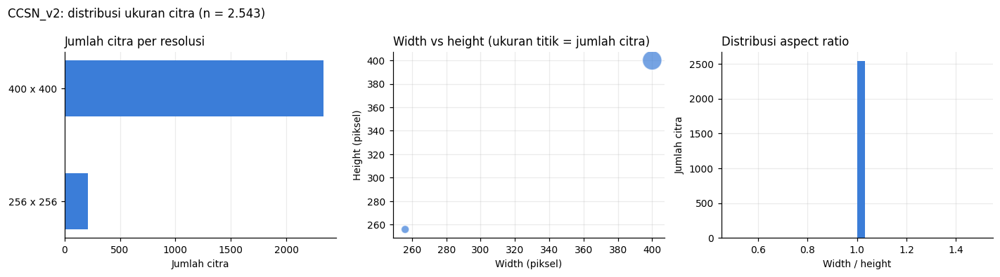

## Dimensi citra: GCD

| Dimensi | Min | Max | Mean | Median |
|---|---:|---:|---:|---:|
| Width (piksel) | 512,00 | 512,00 | 512,00 | 512,00 |
| Height (piksel) | 512,00 | 512,00 | 512,00 | 512,00 |
| Aspect ratio (width/height) | 1,00 | 1,00 | 1,00 | 1,00 |

| Resolusi | Jumlah citra |
|---|---:|
| 512 x 512 | 19.000 |

| Mode warna | Jumlah channel | Jumlah citra |
|---|---:|---:|
| RGB | 3 | 19.000 |

- Seluruh citra berukuran sama: **ya** (1 resolusi unik).
- Variasi resolusi: **tidak ada**.
- Citra grayscale (1 channel): **0**.
- Citra dengan alpha (RGBA/LA): **0**.

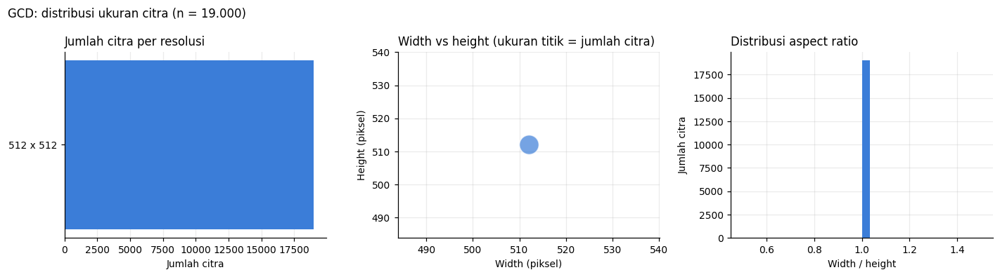

In [6]:
for ds in DATASETS:
    man = R[ds]["manifest"]
    ok = man[man["readable"] == 1].copy()
    ok[["width", "height", "channels"]] = ok[["width", "height", "channels"]].astype(int)
    ok["aspect_ratio"] = ok["width"] / ok["height"]
    R[ds]["ok"] = ok

    dim = pd.DataFrame([{"Dimensi": label, "Min": float(ok[col].min()), "Max": float(ok[col].max()),
                         "Mean": float(ok[col].mean()), "Median": float(ok[col].median())}
                        for label, col in [("Width (piksel)", "width"), ("Height (piksel)", "height"),
                                           ("Aspect ratio (width/height)", "aspect_ratio")]])
    res = (ok.groupby(["width", "height"]).size().reset_index(name="Jumlah citra")
           .sort_values("Jumlah citra", ascending=False, ignore_index=True))
    res.insert(0, "Resolusi", res["width"].astype(str) + " x " + res["height"].astype(str))
    modes = ok.groupby(["mode", "channels"]).size().reset_index(name="Jumlah citra").rename(
        columns={"mode": "Mode warna", "channels": "Jumlah channel"})
    n_gray = int((ok["channels"] == 1).sum())
    n_alpha = int(ok["mode"].isin(["RGBA", "LA", "PA", "RGBa"]).sum())
    R[ds].update(resolutions=res, modes=modes, n_gray=n_gray, n_alpha=n_alpha,
                 same_size=len(res) == 1, all_rgb=set(ok["mode"]) == {"RGB"})

    say(f"## Dimensi citra: {ds}")
    show(dim)
    show(res[["Resolusi", "Jumlah citra"]], max_rows=10)
    show(modes)
    say("\n".join([
        f"- Seluruh citra berukuran sama: **{'ya' if len(res) == 1 else 'tidak'}** ({fint(len(res))} resolusi unik).",
        f"- Variasi resolusi: **{'tidak ada' if len(res) == 1 else 'ada'}**.",
        f"- Citra grayscale (1 channel): **{fint(n_gray)}**.",
        f"- Citra dengan alpha (RGBA/LA): **{fint(n_alpha)}**.",
    ]))
    save_table(dim, ds, "image_dimension_stats")
    save_table(res[["width", "height", "Jumlah citra"]], ds, "resolution_counts")

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    top = res.head(10).iloc[::-1]
    axes[0].barh(top["Resolusi"], top["Jumlah citra"], color=BAR_COLOR, height=0.5)
    axes[0].set_title("Jumlah citra per resolusi", loc="left")
    axes[0].set_xlabel("Jumlah citra")
    axes[0].grid(axis="y", visible=False)
    axes[1].scatter(res["width"], res["height"], s=30 + 300 * res["Jumlah citra"] / res["Jumlah citra"].max(),
                    color=BAR_COLOR, alpha=0.7, edgecolor="white")
    axes[1].set_title("Width vs height (ukuran titik = jumlah citra)", loc="left")
    axes[1].set_xlabel("Width (piksel)")
    axes[1].set_ylabel("Height (piksel)")
    axes[2].hist(ok["aspect_ratio"], bins=30, color=BAR_COLOR)
    axes[2].set_title("Distribusi aspect ratio", loc="left")
    axes[2].set_xlabel("Width / height")
    axes[2].set_ylabel("Jumlah citra")
    fig.suptitle(f"{ds}: distribusi ukuran citra (n = {fint(len(ok))})", x=0.01, ha="left")
    fig.tight_layout()
    save_fig(fig, ds, "image_size_distribution")
    plt.show()

## 6. Visualisasi Sampel Per Kelas

Lima citra per kelas diambil acak dengan seed tetap dari split train (atau split pertama yang tersedia). Citra ditampilkan apa adanya. Judul tiap panel: nama file dan resolusi; nama kelas ada di sisi kiri baris.

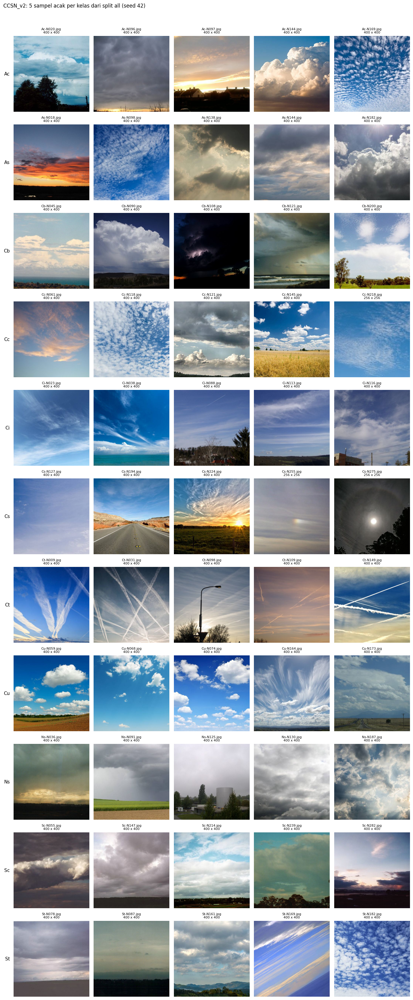

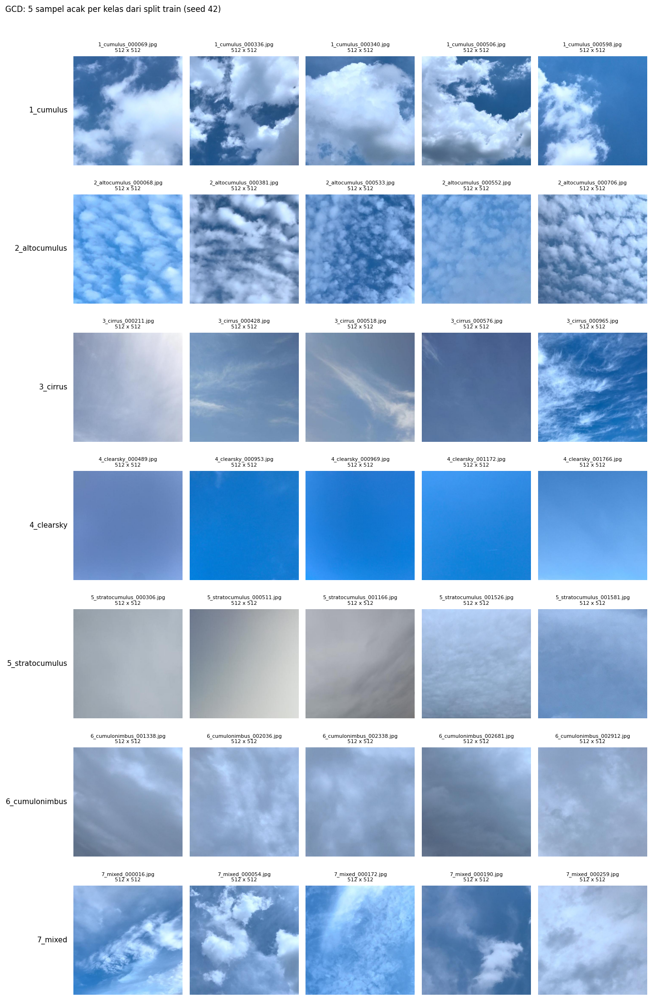

In [7]:
for ds in DATASETS:
    ok = R[ds]["ok"]
    split = "train" if "train" in R[ds]["splits"] else ok["split"].iloc[0]
    classes = R[ds]["classes"]
    rng = np.random.default_rng(SEED)
    picked = []
    for cls in classes:
        pool = ok[(ok["split"] == split) & (ok["class"] == cls)].sort_values("rel_path")
        idx = np.sort(rng.choice(len(pool), size=min(SAMPLES_PER_CLASS, len(pool)), replace=False))
        picked.append(pool.iloc[idx])
    picked = pd.concat(picked, ignore_index=True)
    R[ds]["samples"] = picked
    save_table(picked[["split", "class", "filename", "rel_path", "width", "height"]], ds, "sample_images")

    fig, axes = plt.subplots(len(classes), SAMPLES_PER_CLASS, squeeze=False,
                             figsize=(2.5 * SAMPLES_PER_CLASS, 2.75 * len(classes)))
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    for i, cls in enumerate(classes):
        rows = picked[picked["class"] == cls].reset_index(drop=True)
        axes[i, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10, labelpad=8)
        for j, row in rows.iterrows():
            with Image.open(R[ds]["root"] / row["rel_path"]) as im:
                axes[i, j].imshow(im)
            axes[i, j].set_title(f"{row['filename']}\n{row['width']} x {row['height']}", fontsize=7)
    fig.suptitle(f"{ds}: {SAMPLES_PER_CLASS} sampel acak per kelas dari split {split} (seed {SEED})", x=0.01, ha="left", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save_fig(fig, ds, "sample_images_per_class")
    plt.show()

## 7. Analisis Statistik Piksel

Histogram 256 bin per channel dihitung dari **semua piksel semua citra** pada nilai asli 0-255. Mean, std, min, dan max per channel diturunkan dari histogram itu, sehingga nilainya eksak, bukan rata-rata dari rata-rata. Tidak ada normalisasi yang diterapkan pada data.

## Statistik piksel: CCSN_v2

Statistik per citra dipakai ulang; histogram RGB dihitung.

Mean, Std, Min, dan Max pada skala asli 0-255, dari seluruh piksel:

| Cakupan | Channel | Mean | Std | Min | Max | Mean (skala 0-1) | Std (skala 0-1) |
|---|---|---:|---:|---:|---:|---|---|
| Semua split | Red | 122,30 | 66,89 | 0 | 255 | 0,4796 | 0,2623 |
| Semua split | Green | 133,22 | 60,77 | 0 | 255 | 0,5224 | 0,2383 |
| Semua split | Blue | 142,75 | 65,27 | 0 | 255 | 0,5598 | 0,2560 |
| Semua | Red | 122,30 | 66,89 | 0 | 255 | 0,4796 | 0,2623 |
| Semua | Green | 133,22 | 60,77 | 0 | 255 | 0,5224 | 0,2383 |
| Semua | Blue | 142,75 | 65,27 | 0 | 255 | 0,5598 | 0,2560 |

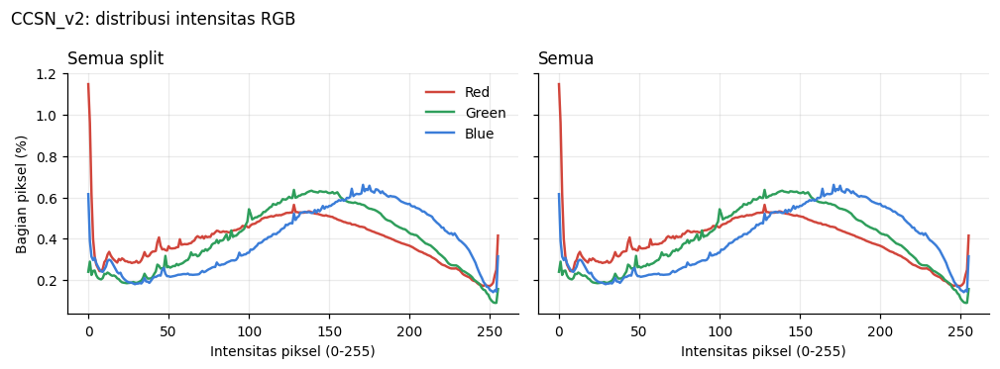

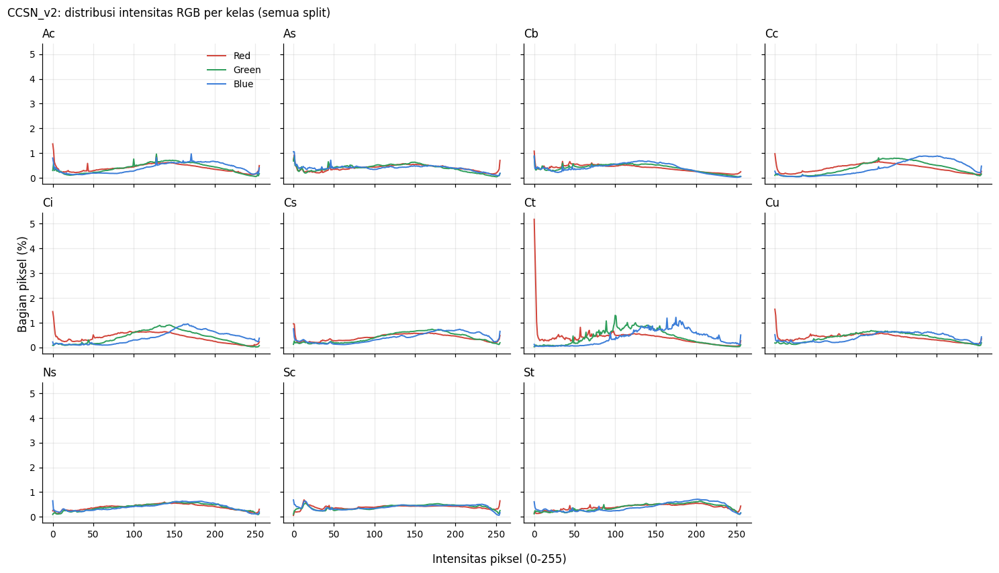

## Statistik piksel: GCD

Statistik per citra dipakai ulang; histogram RGB dipakai ulang.

Mean, Std, Min, dan Max pada skala asli 0-255, dari seluruh piksel:

| Cakupan | Channel | Mean | Std | Min | Max | Mean (skala 0-1) | Std (skala 0-1) |
|---|---|---:|---:|---:|---:|---|---|
| Semua split | Red | 123,05 | 51,97 | 0 | 255 | 0,4826 | 0,2038 |
| Semua split | Green | 156,38 | 32,95 | 0 | 255 | 0,6132 | 0,1292 |
| Semua split | Blue | 193,56 | 35,81 | 0 | 255 | 0,7591 | 0,1404 |
| Train | Red | 123,08 | 49,85 | 0 | 255 | 0,4827 | 0,1955 |
| Train | Green | 156,93 | 32,70 | 0 | 255 | 0,6154 | 0,1282 |
| Train | Blue | 195,63 | 34,94 | 0 | 255 | 0,7672 | 0,1370 |
| Test | Red | 123,03 | 54,24 | 0 | 255 | 0,4825 | 0,2127 |
| Test | Green | 155,76 | 33,21 | 0 | 255 | 0,6108 | 0,1302 |
| Test | Blue | 191,26 | 36,62 | 0 | 255 | 0,7500 | 0,1436 |

Pemeriksaan silang split train: selisih terbesar antara hasil histogram dan `channel_mean_std` = 0,7832 (skala 0-255).

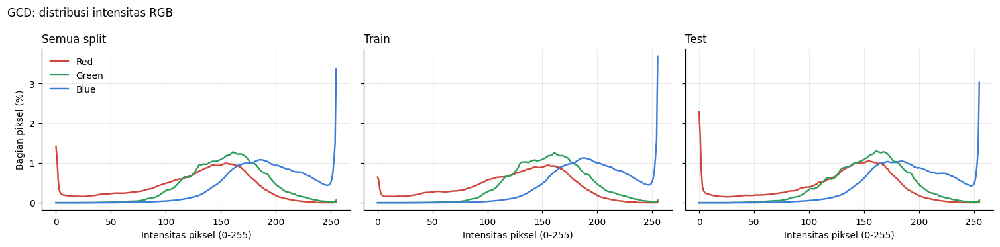

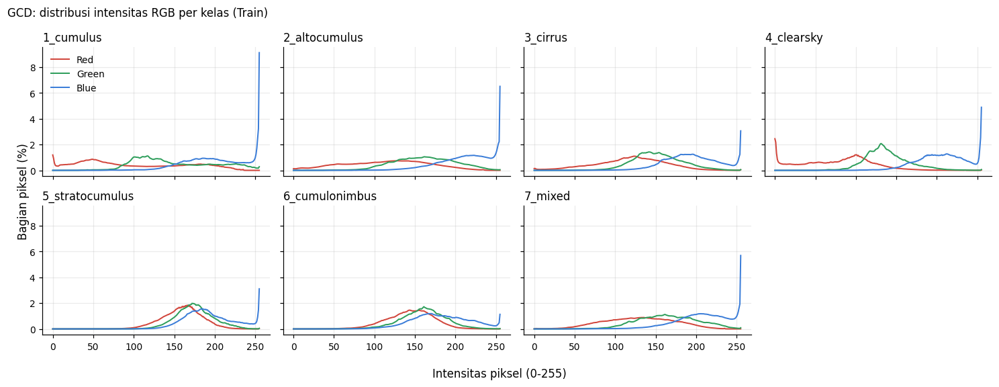

In [8]:
def load_image_stats(ds, ok):
    path = table_path(ds, "image_stats")
    if path.exists() and not FORCE_RECOMPUTE:
        stats = pd.read_csv(path)
        if set(stats["rel_path"]) == set(ok["rel_path"]):
            return stats, "dipakai ulang"
    stats = compute_stats(R[ds]["root"], ok["rel_path"].tolist(), workers=WORKERS)
    stats.to_csv(path, index=False, encoding="utf-8")
    CREATED.append(path)
    return stats, "dihitung"


def load_histogram(ds, ok):
    path = table_path(ds, "rgb_histogram")
    expected = int((ok["width"] * ok["height"]).sum())
    if path.exists() and not FORCE_RECOMPUTE:
        hist = pd.read_csv(path)
        if (hist.groupby("channel")["count"].sum() == expected).all():
            return hist, "dipakai ulang"
    groups = (ok["split"] + "/" + ok["class"]).tolist()
    by_group = histograms_by_group(R[ds]["root"], ok["rel_path"].tolist(), groups, workers=WORKERS)
    parts = []
    for group, arr in sorted(by_group.items()):
        split, cls = group.split("/", 1)
        for c, channel in enumerate(CHANNELS):
            parts.append(pd.DataFrame({"split": split, "class": cls, "channel": channel,
                                       "intensity": np.arange(256), "count": arr[c]}))
    hist = pd.concat(parts, ignore_index=True)
    hist.to_csv(path, index=False, encoding="utf-8")
    CREATED.append(path)
    return hist, "dihitung"


def hist_array(hist, split=None, cls=None):
    part = hist
    if split is not None:
        part = part[part["split"] == split]
    if cls is not None:
        part = part[part["class"] == cls]
    wide = part.groupby(["channel", "intensity"])["count"].sum().unstack(fill_value=0)
    return wide.reindex(index=CHANNELS, columns=range(256), fill_value=0).to_numpy(dtype=np.int64)


for ds in DATASETS:
    ok = R[ds]["ok"]
    stats, how_stats = load_image_stats(ds, ok)
    hist, how_hist = load_histogram(ds, ok)
    df = ok.merge(stats, on="rel_path", validate="one_to_one")
    R[ds].update(df=df, hist=hist)

    scopes = [("Semua split", None)] + [(SPLIT_LABEL[s], s) for s in R[ds]["splits"]]
    rows, pixel = [], {}
    for label, split in scopes:
        st = histogram_stats(hist_array(hist, split))
        pixel[split or "all"] = st
        for c, channel in enumerate(CHANNELS):
            rows.append({"Cakupan": label, "Channel": CHANNEL_NAME[channel], "Mean": st["mean"][c],
                         "Std": st["std"][c], "Min": int(st["min"][c]), "Max": int(st["max"][c]),
                         "Mean (skala 0-1)": fdec(st["mean"][c] / 255, 4), "Std (skala 0-1)": fdec(st["std"][c] / 255, 4)})
    pixel_table = pd.DataFrame(rows)
    R[ds].update(pixel=pixel, pixel_table=pixel_table)

    say(f"## Statistik piksel: {ds}")
    say(f"Statistik per citra {how_stats}; histogram RGB {how_hist}.", report=False)
    say("Mean, Std, Min, dan Max pada skala asli 0-255, dari seluruh piksel:")
    show(pixel_table)
    save_table(pixel_table, ds, "rgb_channel_stats")

    # Pemeriksaan silang dua jalur perhitungan yang independen (histogram vs statistik per citra)
    if R[ds]["same_size"] and "train" in R[ds]["splits"]:
        mean_b, std_b = channel_mean_std(df[df["split"] == "train"])
        gap = max(np.abs(mean_b * 255 - pixel["train"]["mean"]).max(), np.abs(std_b * 255 - pixel["train"]["std"]).max())
        say(f"Pemeriksaan silang split train: selisih terbesar antara hasil histogram dan "
            f"`channel_mean_std` = {fdec(gap, 4)} (skala 0-255).", report=False)

    fig, axes = plt.subplots(1, len(scopes), figsize=(4.6 * len(scopes), 3.4), sharey=True, squeeze=False)
    for ax, (label, split) in zip(axes[0], scopes):
        arr = hist_array(hist, split)
        for c, channel in enumerate(CHANNELS):
            ax.plot(np.arange(256), 100 * arr[c] / arr[c].sum(), color=CHANNEL_COLOR[channel], lw=1.6,
                    label=CHANNEL_NAME[channel])
        ax.set_title(label, loc="left")
        ax.set_xlabel("Intensitas piksel (0-255)")
    axes[0, 0].set_ylabel("Bagian piksel (%)")
    axes[0, 0].legend(frameon=False)
    fig.suptitle(f"{ds}: distribusi intensitas RGB", x=0.01, ha="left")
    fig.tight_layout()
    save_fig(fig, ds, "rgb_distribution")
    plt.show()

    classes = R[ds]["classes"]
    base = "train" if "train" in R[ds]["splits"] else None
    ncols = 4
    nrows = int(np.ceil(len(classes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.6 * nrows), sharex=True, sharey=True, squeeze=False)
    for ax in axes.ravel()[len(classes):]:
        ax.set_visible(False)
    for ax, cls in zip(axes.ravel(), classes):
        arr = hist_array(hist, base, cls)
        for c, channel in enumerate(CHANNELS):
            ax.plot(np.arange(256), 100 * arr[c] / arr[c].sum(), color=CHANNEL_COLOR[channel], lw=1.3,
                    label=CHANNEL_NAME[channel])
        ax.set_title(cls, loc="left")
    axes[0, 0].legend(frameon=False)
    fig.supxlabel("Intensitas piksel (0-255)")
    fig.supylabel("Bagian piksel (%)")
    fig.suptitle(f"{ds}: distribusi intensitas RGB per kelas ({SPLIT_LABEL.get(base, 'semua split')})", x=0.01, ha="left")
    fig.tight_layout()
    save_fig(fig, ds, "rgb_distribution_per_class")
    plt.show()

## 8. Brightness dan Contrast

Pendekatan (dari `src/datasets/image_stats.py`), dihitung per citra pada piksel berskala 0-1 lalu ditampilkan pada skala 0-255:

- luminance tiap piksel: `Y = 0.299 R + 0.587 G + 0.114 B` (bobot ITU-R BT.601);
- **brightness** citra = rata-rata `Y` seluruh piksel;
- **contrast** citra = simpangan baku `Y` seluruh piksel (RMS contrast).

Besarnya perbedaan antar kelas diukur dengan eta-squared, `η² = SS_antar-kelas / SS_total`: bagian variasi antar citra yang dijelaskan oleh label kelas (0 = tidak ada perbedaan antar kelas, 1 = kelas sepenuhnya memisahkan nilai). Sebagai patokan umum, η² ≥ 0,14 disebut besar.

## Brightness dan contrast: CCSN_v2

Skala 0-255, seluruh split digabung.

| Class | n | Brightness mean | Brightness std | Brightness median | Contrast mean | Contrast std | Contrast median |
|---|---:|---:|---:|---:|---:|---:|---:|
| Ac | 221 | 132,24 | 33,16 | 131,84 | 44,47 | 14,59 | 44,24 |
| As | 188 | 119,91 | 39,42 | 122,56 | 44,32 | 12,69 | 44,87 |
| Cb | 242 | 110,18 | 30,10 | 112,16 | 51,32 | 12,53 | 51,12 |
| Cc | 268 | 144,57 | 26,48 | 142,28 | 41,03 | 14,19 | 39,99 |
| Ci | 139 | 130,37 | 25,54 | 129,16 | 40,95 | 13,41 | 41,64 |
| Cs | 287 | 142,66 | 30,38 | 142,89 | 47,46 | 17,30 | 48,14 |
| Ct | 200 | 120,17 | 28,56 | 127,34 | 34,36 | 13,83 | 34,19 |
| Cu | 182 | 126,39 | 29,45 | 123,32 | 47,72 | 12,62 | 47,58 |
| Ns | 274 | 132,11 | 32,78 | 132,94 | 49,97 | 13,79 | 50,33 |
| Sc | 340 | 132,91 | 39,08 | 138,79 | 55,31 | 17,60 | 54,04 |
| St | 202 | 144,36 | 33,16 | 145,89 | 52,76 | 16,33 | 52,72 |

- Brightness: rata-rata kelas dari 110,18 (Cb) sampai 144,57 (Cc); η² = 0,096.
- Contrast: rata-rata kelas dari 34,36 (Ct) sampai 55,31 (Sc); η² = 0,135.

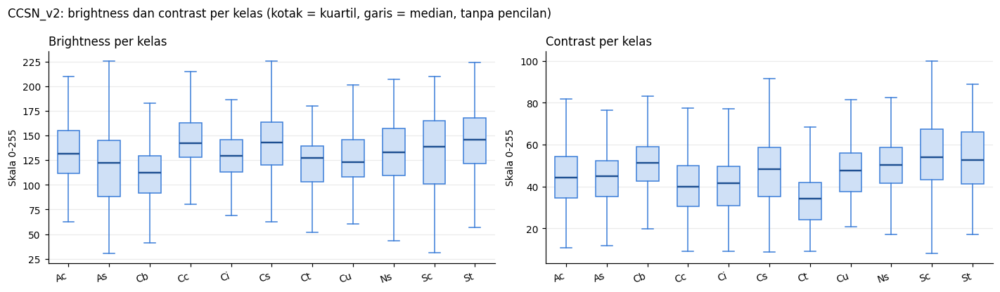

## Brightness dan contrast: GCD

Skala 0-255, seluruh split digabung.

| Class | n | Brightness mean | Brightness std | Brightness median | Contrast mean | Contrast std | Contrast median |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1_cumulus | 1.525 | 139,73 | 19,71 | 140,98 | 42,23 | 12,70 | 44,16 |
| 2_altocumulus | 1.475 | 155,40 | 24,56 | 158,07 | 26,14 | 11,06 | 24,56 |
| 3_cirrus | 1.906 | 143,33 | 21,71 | 144,54 | 22,62 | 10,53 | 21,92 |
| 4_clearsky | 3.739 | 122,62 | 24,93 | 122,39 | 12,58 | 7,44 | 11,29 |
| 5_stratocumulus | 3.636 | 171,40 | 19,16 | 170,46 | 11,75 | 6,06 | 10,61 |
| 6_cumulonimbus | 5.764 | 158,64 | 18,45 | 159,92 | 17,99 | 8,51 | 16,51 |
| 7_mixed | 955 | 157,89 | 17,35 | 158,29 | 29,68 | 11,69 | 29,82 |

- Brightness: rata-rata kelas dari 122,62 (4_clearsky) sampai 171,40 (5_stratocumulus); η² = 0,387.
- Contrast: rata-rata kelas dari 11,75 (5_stratocumulus) sampai 42,23 (1_cumulus); η² = 0,475.

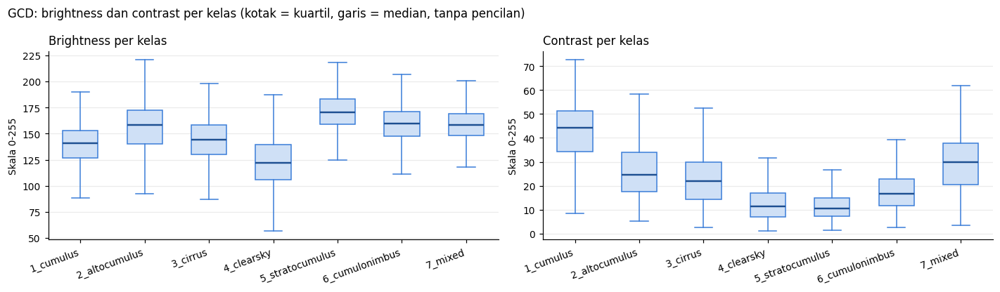

Perbandingan train dan test per kelas. `d` = selisih rata-rata (test − train) dibagi simpangan baku gabungan (Cohen's d); |d| ≥ 0,5 berarti pergeseran sedang, |d| ≥ 0,8 besar.

| Class | Brightness train | Brightness test | d brightness | Contrast train | Contrast test | d contrast |
|---|---:|---:|---:|---:|---:|---:|
| 1_cumulus | 141,25 | 138,15 | -0,16 | 47,40 | 36,89 | -0,91 |
| 2_altocumulus | 153,37 | 157,36 | 0,16 | 28,26 | 24,09 | -0,38 |
| 3_cirrus | 147,01 | 137,69 | -0,44 | 21,19 | 24,80 | 0,35 |
| 4_clearsky | 127,26 | 116,34 | -0,45 | 12,57 | 12,60 | 0,00 |
| 5_stratocumulus | 172,71 | 170,06 | -0,14 | 12,21 | 11,28 | -0,15 |
| 6_cumulonimbus | 157,92 | 159,42 | 0,08 | 19,19 | 16,69 | -0,30 |
| 7_mixed | 159,02 | 157,24 | -0,10 | 32,50 | 28,07 | -0,39 |

In [9]:
def eta_squared(values, groups):
    grand = values.mean()
    between = sum(len(v) * (v.mean() - grand) ** 2 for _, v in values.groupby(groups))
    return between / ((values - grand) ** 2).sum()


def cohen_d(a, b):
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / pooled if pooled > 0 else np.nan


for ds in DATASETS:
    df = R[ds]["df"]
    df["brightness_255"] = df["brightness"] * 255
    df["contrast_255"] = df["contrast"] * 255
    classes = R[ds]["classes"]

    per_class = (df.groupby("class").agg(
        n=("rel_path", "size"),
        **{"Brightness mean": ("brightness_255", "mean"), "Brightness std": ("brightness_255", "std"),
           "Brightness median": ("brightness_255", "median"), "Contrast mean": ("contrast_255", "mean"),
           "Contrast std": ("contrast_255", "std"), "Contrast median": ("contrast_255", "median")})
        .reindex(classes).reset_index().rename(columns={"class": "Class"}))
    eta = {f: eta_squared(df[f], df["class"]) for f in ["brightness_255", "contrast_255"]}
    R[ds].update(bc_table=per_class, eta=eta)

    say(f"## Brightness dan contrast: {ds}")
    say("Skala 0-255, seluruh split digabung.", report=False)
    show(per_class)
    save_table(per_class, ds, "brightness_contrast_per_class")
    b, c = per_class["Brightness mean"], per_class["Contrast mean"]
    say("\n".join([
        f"- Brightness: rata-rata kelas dari {fdec(b.min())} ({per_class.loc[b.idxmin(), 'Class']}) sampai "
        f"{fdec(b.max())} ({per_class.loc[b.idxmax(), 'Class']}); η² = {fdec(eta['brightness_255'], 3)}.",
        f"- Contrast: rata-rata kelas dari {fdec(c.min())} ({per_class.loc[c.idxmin(), 'Class']}) sampai "
        f"{fdec(c.max())} ({per_class.loc[c.idxmax(), 'Class']}); η² = {fdec(eta['contrast_255'], 3)}.",
    ]))

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    for ax, col, title in [(axes[0], "brightness_255", "Brightness per kelas"), (axes[1], "contrast_255", "Contrast per kelas")]:
        ax.boxplot([df.loc[df["class"] == cls, col] for cls in classes], showfliers=False, patch_artist=True, widths=0.55,
                   boxprops={"facecolor": "#cfe0f6", "edgecolor": BAR_COLOR}, medianprops={"color": "#1d4f91", "linewidth": 1.6},
                   whiskerprops={"color": BAR_COLOR}, capprops={"color": BAR_COLOR})
        ax.set_xticks(range(1, len(classes) + 1))
        ax.set_xticklabels(classes, rotation=20, ha="right")
        ax.set_title(title, loc="left")
        ax.set_ylabel("Skala 0-255")
        ax.grid(axis="x", visible=False)
    fig.suptitle(f"{ds}: brightness dan contrast per kelas (kotak = kuartil, garis = median, tanpa pencilan)", x=0.01, ha="left")
    fig.tight_layout()
    save_fig(fig, ds, "brightness_contrast_per_class")
    plt.show()

    # Perbandingan antar split per kelas: apakah train dan test berasal dari sebaran yang serupa?
    if {"train", "test"} <= set(R[ds]["splits"]):
        rows = []
        for cls in classes:
            a = df[(df["class"] == cls) & (df["split"] == "train")]
            t = df[(df["class"] == cls) & (df["split"] == "test")]
            rows.append({"Class": cls,
                         "Brightness train": a["brightness_255"].mean(), "Brightness test": t["brightness_255"].mean(),
                         "d brightness": cohen_d(a["brightness_255"], t["brightness_255"]),
                         "Contrast train": a["contrast_255"].mean(), "Contrast test": t["contrast_255"].mean(),
                         "d contrast": cohen_d(a["contrast_255"], t["contrast_255"])})
        shift = pd.DataFrame(rows)
        R[ds]["shift"] = shift
        say("Perbandingan train dan test per kelas. `d` = selisih rata-rata (test − train) dibagi simpangan baku "
            "gabungan (Cohen's d); |d| ≥ 0,5 berarti pergeseran sedang, |d| ≥ 0,8 besar.")
        show(shift)
        save_table(shift, ds, "train_test_shift_per_class")

## 9. Analisis Ketidakseimbangan Kelas

Hanya mendokumentasikan kondisi asli. Tidak ada oversampling atau undersampling. Tingkat imbalance memakai rasio kelas terbesar terhadap kelas terkecil: < 1,5 seimbang; 1,5 sampai < 3 ringan; 3 sampai < 10 sedang; ≥ 10 berat (konvensi notebook ini).

In [10]:
def imbalance_level(ratio):
    return "seimbang" if ratio < 1.5 else "ringan" if ratio < 3 else "sedang" if ratio < 10 else "berat"


for ds in DATASETS:
    tab = R[ds]["dist"]
    total = tab["Total"]
    overall = pd.DataFrame({"Class": tab.index, "Samples": total.to_numpy(), "Percentage": (100 * total / total.sum()).to_numpy()})
    wide = pd.DataFrame({"Class": tab.index})
    for s in R[ds]["splits"]:
        wide[f"{SPLIT_LABEL[s]} n"] = tab[s].to_numpy()
        wide[f"{SPLIT_LABEL[s]} %"] = (100 * tab[s] / tab[s].sum()).to_numpy()
    imb = R[ds]["imbalance"].copy()
    imb["Tingkat imbalance"] = imb["Rasio terbesar/terkecil"].map(imbalance_level)
    R[ds].update(imbalance=imb, class_share=wide)

    say(f"## Ketidakseimbangan kelas: {ds}")
    show(overall)
    say("Proporsi per split:")
    show(wide)
    show(imb[["Split", "Kelas terbesar", "n terbesar", "Kelas terkecil", "n terkecil", "Rasio terbesar/terkecil", "Tingkat imbalance"]])
    save_table(overall, ds, "class_percentage")
    save_table(wide, ds, "class_percentage_per_split")

## Ketidakseimbangan kelas: CCSN_v2

| Class | Samples | Percentage |
|---|---:|---:|
| Ac | 221 | 8,69 |
| As | 188 | 7,39 |
| Cb | 242 | 9,52 |
| Cc | 268 | 10,54 |
| Ci | 139 | 5,47 |
| Cs | 287 | 11,29 |
| Ct | 200 | 7,86 |
| Cu | 182 | 7,16 |
| Ns | 274 | 10,77 |
| Sc | 340 | 13,37 |
| St | 202 | 7,94 |

Proporsi per split:

| Class | Semua n | Semua % |
|---|---:|---:|
| Ac | 221 | 8,69 |
| As | 188 | 7,39 |
| Cb | 242 | 9,52 |
| Cc | 268 | 10,54 |
| Ci | 139 | 5,47 |
| Cs | 287 | 11,29 |
| Ct | 200 | 7,86 |
| Cu | 182 | 7,16 |
| Ns | 274 | 10,77 |
| Sc | 340 | 13,37 |
| St | 202 | 7,94 |

| Split | Kelas terbesar | n terbesar | Kelas terkecil | n terkecil | Rasio terbesar/terkecil | Tingkat imbalance |
|---|---|---:|---|---:|---:|---|
| Semua | Sc | 340 | Ci | 139 | 2,45 | ringan |
| Semua split | Sc | 340 | Ci | 139 | 2,45 | ringan |

## Ketidakseimbangan kelas: GCD

| Class | Samples | Percentage |
|---|---:|---:|
| 1_cumulus | 1.525 | 8,03 |
| 2_altocumulus | 1.475 | 7,76 |
| 3_cirrus | 1.906 | 10,03 |
| 4_clearsky | 3.739 | 19,68 |
| 5_stratocumulus | 3.636 | 19,14 |
| 6_cumulonimbus | 5.764 | 30,34 |
| 7_mixed | 955 | 5,03 |

Proporsi per split:

| Class | Train n | Train % | Test n | Test % |
|---|---:|---:|---:|---:|
| 1_cumulus | 775 | 7,75 | 750 | 8,33 |
| 2_altocumulus | 725 | 7,25 | 750 | 8,33 |
| 3_cirrus | 1.153 | 11,53 | 753 | 8,37 |
| 4_clearsky | 2.150 | 21,50 | 1.589 | 17,66 |
| 5_stratocumulus | 1.846 | 18,46 | 1.790 | 19,89 |
| 6_cumulonimbus | 3.003 | 30,03 | 2.761 | 30,68 |
| 7_mixed | 348 | 3,48 | 607 | 6,74 |

| Split | Kelas terbesar | n terbesar | Kelas terkecil | n terkecil | Rasio terbesar/terkecil | Tingkat imbalance |
|---|---|---:|---|---:|---:|---|
| Train | 6_cumulonimbus | 3.003 | 7_mixed | 348 | 8,63 | sedang |
| Test | 6_cumulonimbus | 2.761 | 7_mixed | 607 | 4,55 | sedang |
| Semua split | 6_cumulonimbus | 5.764 | 7_mixed | 955 | 6,04 | sedang |

## 10. Pemeriksaan Duplikasi

Tiga tingkat pemeriksaan, dari yang pasti ke yang berupa kandidat:

1. **Berkas identik**: SHA-256 isi berkas sama.
2. **Piksel identik**: hash piksel hasil decode sama (menangkap citra sama yang disimpan ulang).
3. **Kandidat near-duplicate**: dHash 16 x 16 (256 bit) dengan jarak Hamming ≤ 10, **bukan** piksel identik.

Catatan metode untuk tingkat 3. dHash membandingkan kecerahan piksel bersebelahan pada citra yang dikecilkan. Pada citra yang hampir seragam atau hanya berupa gradasi halus (langit cerah, mendung rata), hampir semua bit bernilai sama, sehingga citra yang berbeda pun tampak "mirip". Karena itu pasangan hanya dihitung bila kedua citra memiliki dHash yang informatif: 15% sampai 85% bitnya bernilai 1. Hasilnya tetap **kandidat** yang memerlukan tinjauan visual, bukan bukti duplikasi.

Duplikat lintas split ditandai sebagai potensi data leakage. Tidak ada berkas yang dihapus.

## Duplikasi: CCSN_v2

| Pemeriksaan | Status | Pasangan berkas identik | Pasangan piksel identik | Kandidat near-duplicate |
|---|---|---:|---:|---:|
| Dalam Semua | diperiksa | 17 | 17 | 130 |
| Train dan Validation | tidak dapat diperiksa (split Train, Validation tidak ada) | - | - | - |
| Train dan Test | tidak dapat diperiksa (split Train, Test tidak ada) | - | - | - |
| Validation dan Test | tidak dapat diperiksa (split Validation, Test tidak ada) | - | - | - |

Rincian pasangan berkas identik menurut letak dan kelas:

| Letak pasangan | Kelas | Jumlah pasangan |
|---|---|---:|
| dalam all | Ac / As | 2 |
| dalam all | As | 1 |
| dalam all | Cb | 6 |
| dalam all | Cc | 2 |
| dalam all | Cc / Cs | 1 |
| dalam all | Cu | 5 |

- Pasangan berkas identik: **17**; berkas yang terlibat: 34.
- Pasangan piksel identik yang berkasnya berbeda (disimpan ulang): **0**.
- Pasangan identik dengan label kelas berbeda: **3**.
- Citra dengan dHash informatif: 2.456 dari 2.543; sisanya (87) tidak dapat dinilai dengan metode ini.
- Kandidat near-duplicate (jarak Hamming ≤ 10, bukan piksel identik): **130** pasangan, 0 di antaranya lintas split.

Kandidat near-duplicate menurut letak dan kelas:

| Letak pasangan | Kelas | Jumlah pasangan | Jarak Hamming terkecil | Jarak Hamming terbesar |
|---|---|---:|---:|---:|
| dalam all | Ac / As | 1 | 4 | 4 |
| dalam all | Ac / Cc | 6 | 0 | 6 |
| dalam all | Ac / Ns | 1 | 8 | 8 |
| dalam all | Ac / Sc | 1 | 4 | 4 |
| dalam all | As / Cb | 4 | 0 | 5 |
| dalam all | As / Cc | 1 | 2 | 2 |
| dalam all | As / Ci | 2 | 3 | 6 |
| dalam all | As / Cs | 2 | 9 | 10 |
| dalam all | As / Cu | 2 | 3 | 3 |
| dalam all | As / Ns | 1 | 3 | 3 |
| dalam all | As / Sc | 1 | 10 | 10 |
| dalam all | As / St | 3 | 1 | 2 |
| dalam all | Cb / Ci | 1 | 3 | 3 |
| dalam all | Cb / Cu | 10 | 1 | 3 |
| dalam all | Cc | 2 | 4 | 5 |
| dalam all | Cc / Ci | 1 | 2 | 2 |
| dalam all | Cc / Cs | 12 | 0 | 4 |
| dalam all | Cc / Ns | 2 | 0 | 4 |
| dalam all | Cc / St | 3 | 1 | 3 |
| dalam all | Ci / Cs | 4 | 0 | 3 |
| dalam all | Ci / Ct | 1 | 4 | 4 |
| dalam all | Ci / Cu | 2 | 2 | 2 |
| dalam all | Ci / St | 2 | 2 | 4 |
| dalam all | Cs | 7 | 2 | 10 |
| dalam all | Cs / Cu | 4 | 3 | 10 |

*Menampilkan 25 dari 34 baris.*

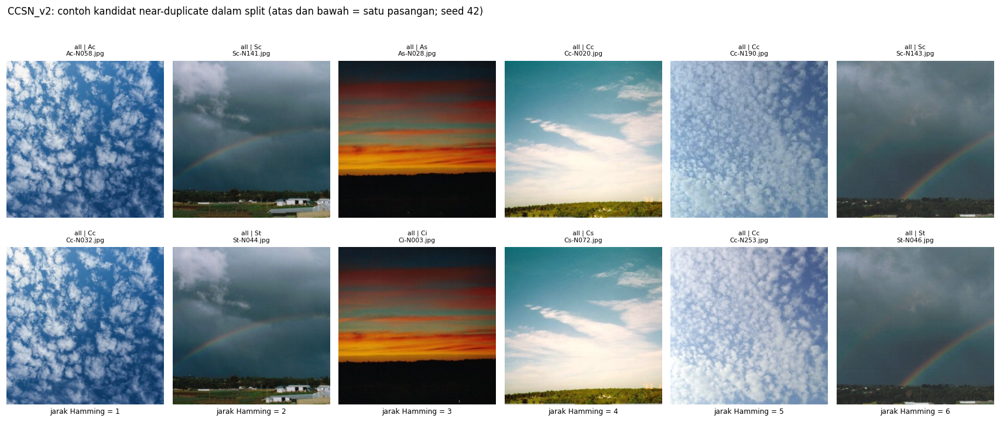

## Duplikasi: GCD

| Pemeriksaan | Status | Pasangan berkas identik | Pasangan piksel identik | Kandidat near-duplicate |
|---|---|---:|---:|---:|
| Dalam Train | diperiksa | 1 | 1 | 3 |
| Dalam Validation | tidak dapat diperiksa (split Validation tidak ada) | - | - | - |
| Dalam Test | diperiksa | 2 | 2 | 6 |
| Train dan Validation | tidak dapat diperiksa (split Validation tidak ada) | - | - | - |
| Train dan Test | diperiksa | 156 | 156 | 36 |
| Validation dan Test | tidak dapat diperiksa (split Validation tidak ada) | - | - | - |

Rincian pasangan berkas identik menurut letak dan kelas:

| Letak pasangan | Kelas | Jumlah pasangan |
|---|---|---:|
| dalam test | 1_cumulus | 1 |
| dalam test | 5_stratocumulus | 1 |
| dalam train | 7_mixed | 1 |
| train-test | 4_clearsky | 155 |
| train-test | 7_mixed | 1 |

- Pasangan berkas identik: **159**; berkas yang terlibat: 318.
- Pasangan piksel identik yang berkasnya berbeda (disimpan ulang): **0**.
- Pasangan identik dengan label kelas berbeda: **0**.
- Citra dengan dHash informatif: 14.648 dari 19.000; sisanya (4.352) tidak dapat dinilai dengan metode ini.
- Kandidat near-duplicate (jarak Hamming ≤ 10, bukan piksel identik): **45** pasangan, 36 di antaranya lintas split.

Kandidat near-duplicate menurut letak dan kelas:

| Letak pasangan | Kelas | Jumlah pasangan | Jarak Hamming terkecil | Jarak Hamming terbesar |
|---|---|---:|---:|---:|
| dalam test | 1_cumulus | 2 | 3 | 5 |
| dalam test | 4_clearsky / 5_stratocumulus | 2 | 7 | 10 |
| dalam test | 6_cumulonimbus | 1 | 8 | 8 |
| dalam test | 7_mixed | 1 | 10 | 10 |
| dalam train | 1_cumulus | 1 | 5 | 5 |
| dalam train | 2_altocumulus / 5_stratocumulus | 1 | 4 | 4 |
| dalam train | 7_mixed | 1 | 8 | 8 |
| train-test | 3_cirrus | 1 | 8 | 8 |
| train-test | 4_clearsky | 32 | 0 | 2 |
| train-test | 4_clearsky / 5_stratocumulus | 2 | 7 | 9 |
| train-test | 5_stratocumulus | 1 | 6 | 6 |

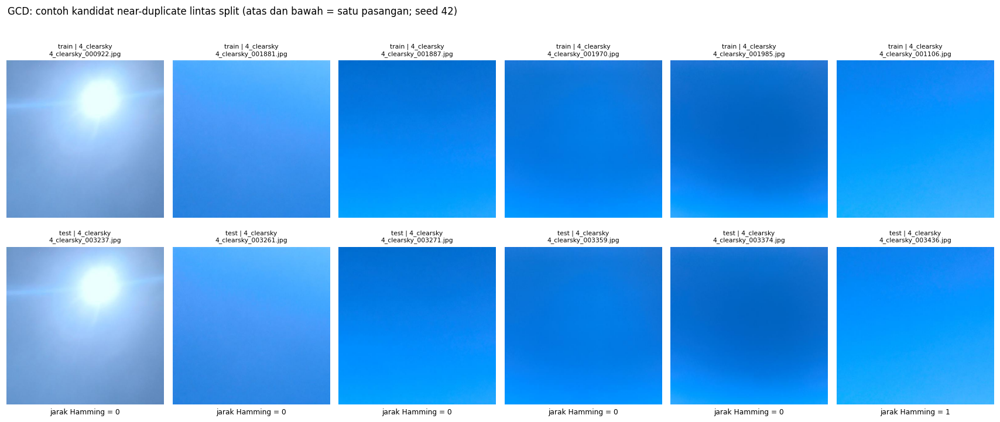

**Observasi visual** (subjektif; dari 6 pasangan pada gambar di atas, bukan hasil perhitungan): Keenam pasangan lintas split yang ditampilkan (semuanya 4_clearsky, jarak Hamming 0 sampai 1) tampak sebagai citra yang sama, termasuk satu pasangan dengan silau matahari di posisi yang sama. Hash pikselnya berbeda, sehingga kemungkinan besar ini citra yang sama yang disimpan atau dikompresi ulang. Kandidat lain di tabel belum ditinjau.

In [11]:
PAIR_COLS = ["file_a", "split_a", "class_a", "file_b", "split_b", "class_b", "method", "location"]


def split_rank(s):
    return SPLIT_ORDER.index(s) if s in SPLIT_ORDER else len(SPLIT_ORDER)


def location(a, b):
    if a == b:
        return f"dalam {a}"
    a, b = sorted([a, b], key=split_rank)
    return f"{a}-{b}"


def ordered(frame):
    """Urutkan menurut split lalu path, agar file_a selalu berada di split yang lebih awal."""
    return frame.assign(_rank=frame["split"].map(split_rank)).sort_values(["_rank", "rel_path"]).reset_index(drop=True)


def group_pairs(frame, key, method):
    """Semua pasangan berkas yang memiliki nilai key sama."""
    dup = ordered(frame[(frame[key] != "") & frame.duplicated(key, keep=False)])
    rows = []
    for _, g in dup.groupby(key):
        for a, b in combinations(g.to_dict("records"), 2):
            rows.append({"file_a": a["rel_path"], "split_a": a["split"], "class_a": a["class"],
                         "file_b": b["rel_path"], "split_b": b["split"], "class_b": b["class"],
                         "method": method, "location": location(a["split"], b["split"])})
    return pd.DataFrame(rows, columns=PAIR_COLS)


popcount = np.bitwise_count if hasattr(np, "bitwise_count") else (
    lambda x, _lut=np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8): _lut[x])


def hash_bits(dhash):
    return np.frombuffer(bytes.fromhex("".join(dhash)), dtype=np.uint8).reshape(len(dhash), -1)


def near_duplicate_pairs(frame, max_distance, chunk=256):
    """Pasangan dengan jarak Hamming dHash <= max_distance, tidak termasuk pasangan piksel identik."""
    frame = ordered(frame)
    cols = PAIR_COLS + ["hamming"]
    if len(frame) < 2:
        return pd.DataFrame(columns=cols)
    bits = hash_bits(frame["dhash"])
    left, right, dist_all = [], [], []
    for start in range(0, len(bits), chunk):
        dist = popcount(bits[start:start + chunk, None, :] ^ bits[None, :, :]).sum(axis=-1, dtype=np.int32)
        ii, jj = np.nonzero(dist <= max_distance)
        keep = (ii + start) < jj
        left.append(ii[keep] + start)
        right.append(jj[keep])
        dist_all.append(dist[ii[keep], jj[keep]])
    a, b, d = np.concatenate(left), np.concatenate(right), np.concatenate(dist_all)
    pixels = frame["pixel_sha256"].to_numpy()
    keep = pixels[a] != pixels[b]
    a, b, d = a[keep], b[keep], d[keep]
    path, split, cls = (frame[c].to_numpy() for c in ["rel_path", "split", "class"])
    return pd.DataFrame({"file_a": path[a], "split_a": split[a], "class_a": cls[a],
                         "file_b": path[b], "split_b": split[b], "class_b": cls[b], "method": "dHash 16x16",
                         "location": [location(x, y) for x, y in zip(split[a], split[b])], "hamming": d}, columns=cols)


def pair_class(pairs):
    return np.where(pairs["class_a"] == pairs["class_b"], pairs["class_a"], pairs["class_a"] + " / " + pairs["class_b"])


for ds in DATASETS:
    man, df = R[ds]["manifest"], R[ds]["df"]
    splits = R[ds]["splits"]
    byte_pairs = group_pairs(man, "sha256", "SHA-256 isi berkas")
    pixel_pairs = group_pairs(man[man["readable"] == 1], "pixel_sha256", "hash piksel")
    byte_keys = set(zip(byte_pairs["file_a"], byte_pairs["file_b"]))
    pixel_only = pixel_pairs[[k not in byte_keys for k in zip(pixel_pairs["file_a"], pixel_pairs["file_b"])]]
    df["dhash_ones"] = popcount(hash_bits(df["dhash"])).sum(axis=1) / 256
    informative = df[df["dhash_ones"].between(*HASH_BALANCE)]
    near = near_duplicate_pairs(informative, NEAR_DUP_MAX_HAMMING)
    near = near.sort_values(["hamming", "file_a", "file_b"], ignore_index=True)
    R[ds].update(byte_pairs=byte_pairs, pixel_pairs=pixel_pairs, pixel_only=pixel_only, near=near,
                 n_informative=len(informative))

    checks = [("Dalam " + SPLIT_LABEL[s], [s], f"dalam {s}") for s in disp_splits(ds)]
    checks += [("Train dan Validation", ["train", "val"], "train-val"),
               ("Train dan Test", ["train", "test"], "train-test"),
               ("Validation dan Test", ["val", "test"], "val-test")]
    rows = []
    for label, needed, loc in checks:
        absent = [SPLIT_LABEL[s] for s in needed if s not in splits]
        if absent:
            rows.append({"Pemeriksaan": label, "Status": f"tidak dapat diperiksa (split {', '.join(absent)} tidak ada)",
                         "Pasangan berkas identik": None, "Pasangan piksel identik": None,
                         "Kandidat near-duplicate": None})
        else:
            rows.append({"Pemeriksaan": label, "Status": "diperiksa",
                         "Pasangan berkas identik": int((byte_pairs["location"] == loc).sum()),
                         "Pasangan piksel identik": int((pixel_pairs["location"] == loc).sum()),
                         "Kandidat near-duplicate": int((near["location"] == loc).sum())})
    dup_summary = pd.DataFrame(rows)
    count_cols = ["Pasangan berkas identik", "Pasangan piksel identik", "Kandidat near-duplicate"]
    dup_summary[count_cols] = dup_summary[count_cols].astype("Int64")
    by_class = (byte_pairs.assign(Kelas=pair_class(byte_pairs)).groupby(["location", "Kelas"]).size()
                .reset_index(name="Jumlah pasangan").rename(columns={"location": "Letak pasangan"}))
    cross_class = int((byte_pairs["class_a"] != byte_pairs["class_b"]).sum())
    near_cross = near[near["split_a"] != near["split_b"]]
    R[ds].update(dup_summary=dup_summary, dup_by_class=by_class, dup_cross_class=cross_class)

    say(f"## Duplikasi: {ds}")
    show(dup_summary)
    say("Rincian pasangan berkas identik menurut letak dan kelas:")
    show(by_class)
    say("\n".join([
        f"- Pasangan berkas identik: **{fint(len(byte_pairs))}**; berkas yang terlibat: "
        f"{fint(len(set(byte_pairs['file_a']) | set(byte_pairs['file_b'])))}.",
        f"- Pasangan piksel identik yang berkasnya berbeda (disimpan ulang): **{fint(len(pixel_only))}**.",
        f"- Pasangan identik dengan label kelas berbeda: **{fint(cross_class)}**.",
        f"- Citra dengan dHash informatif: {fint(len(informative))} dari {fint(len(df))}; sisanya "
        f"({fint(len(df) - len(informative))}) tidak dapat dinilai dengan metode ini.",
        f"- Kandidat near-duplicate (jarak Hamming ≤ {NEAR_DUP_MAX_HAMMING}, bukan piksel identik): **{fint(len(near))}** pasangan, "
        f"{fint(len(near_cross))} di antaranya lintas split.",
    ]))
    save_table(pd.concat([byte_pairs, pixel_only], ignore_index=True), ds, "duplicate_pairs")
    save_table(near, ds, "near_duplicate_candidates")

    if len(near):
        near_class = (near.assign(Kelas=pair_class(near)).groupby(["location", "Kelas"])
                      .agg(**{"Jumlah pasangan": ("hamming", "size"), "Jarak Hamming terkecil": ("hamming", "min"),
                              "Jarak Hamming terbesar": ("hamming", "max")})
                      .reset_index().rename(columns={"location": "Letak pasangan"}))
        say("Kandidat near-duplicate menurut letak dan kelas:")
        show(near_class, max_rows=25)
        pool = near_cross if len(near_cross) else near
        n_show = min(6, len(pool))
        rng = np.random.default_rng(SEED)
        chosen = pool.iloc[np.sort(rng.choice(len(pool), size=n_show, replace=False))]
        fig, axes = plt.subplots(2, n_show, figsize=(2.6 * n_show, 6.6), squeeze=False)
        for ax in axes.ravel():
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
        for k, row in enumerate(chosen.itertuples(index=False)):
            for r, (path, split, cls) in enumerate([(row.file_a, row.split_a, row.class_a), (row.file_b, row.split_b, row.class_b)]):
                with Image.open(R[ds]["root"] / path) as im:
                    axes[r, k].imshow(im)
                axes[r, k].set_title(f"{split} | {cls}\n{Path(path).name}", fontsize=7)
            axes[1, k].set_xlabel(f"jarak Hamming = {row.hamming}", fontsize=8)
        fig.suptitle(f"{ds}: contoh kandidat near-duplicate {'lintas split' if len(near_cross) else 'dalam split'} "
                     f"(atas dan bawah = satu pasangan; seed {SEED})", x=0.01, ha="left", y=0.995)
        fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.2)
        save_fig(fig, ds, "near_duplicate_candidates")
        plt.show()
        note = VISUAL_NOTES.get(ds, {}).get("near_duplicate")
        if note:
            say(f"**Observasi visual** (subjektif; dari {n_show} pasangan pada gambar di atas, bukan hasil perhitungan): {note}")

## 11. Pemeriksaan Potensi Data Leakage

Tiga pemeriksaan lintas split dilaporkan terpisah: nama file yang sama, hash berkas yang sama, dan citra identik (piksel sama). Hanya pasangan yang kedua berkasnya berada di split berbeda yang masuk daftar.

In [12]:
LEAK_COLS = {"file_a": "File A", "split_a": "Split A", "file_b": "File B", "split_b": "Split B", "method": "Detection Method"}

for ds in DATASETS:
    man = R[ds]["manifest"].copy()
    man["filename_key"] = man["filename"].str.lower()
    name_pairs = group_pairs(man, "filename_key", "nama file sama")
    reports = [("Nama file yang sama antar split", name_pairs),
               ("Hash berkas (SHA-256) yang sama antar split", R[ds]["byte_pairs"]),
               ("Citra identik (piksel sama) antar split", R[ds]["pixel_pairs"])]
    say(f"## Potensi data leakage: {ds}")
    if len(R[ds]["splits"]) < 2:
        say("Hanya satu split tersedia, sehingga pemeriksaan lintas split tidak dapat dilakukan.")
    leak_tables = []
    for title, pairs in reports:
        cross = pairs[pairs["split_a"] != pairs["split_b"]].reset_index(drop=True)
        leak_tables.append(cross)
        by_loc = ", ".join(f"{loc}: {fint(n)}" for loc, n in cross["location"].value_counts().items()) or "tidak ada"
        say(f"**{title}: {fint(len(cross))} pasangan** ({by_loc}).")
        if len(cross):
            show(cross[list(LEAK_COLS)].rename(columns=LEAK_COLS), max_rows=10)
    leak = pd.concat(leak_tables, ignore_index=True)
    R[ds].update(leak=leak, leak_name=len(leak_tables[0]), leak_hash=len(leak_tables[1]), leak_pixel=len(leak_tables[2]))
    save_table(leak[list(LEAK_COLS)].rename(columns=LEAK_COLS), ds, "cross_split_leakage")

    test_side = leak_tables[1][leak_tables[1]["split_b"] == "test"]
    n_test = int((man["split"] == "test").sum())
    if len(test_side) and n_test:
        dup_test = test_side.drop_duplicates("file_b")
        parts = []
        for cls, n in dup_test["class_b"].value_counts().items():
            n_cls = int(((man["split"] == "test") & (man["class"] == cls)).sum())
            parts.append(f"{cls}: {fint(n)} dari {fint(n_cls)} citra test kelas itu ({fdec(100 * n / n_cls)}%)")
        say(f"Citra test yang salinan identiknya ada di split lain: **{fint(len(dup_test))}** dari {fint(n_test)} "
            f"({fdec(100 * len(dup_test) / n_test)}% test). Per kelas: " + "; ".join(parts) + ".")
        R[ds]["leak_test_files"] = len(dup_test)

## Potensi data leakage: CCSN_v2

Hanya satu split tersedia, sehingga pemeriksaan lintas split tidak dapat dilakukan.

**Nama file yang sama antar split: 0 pasangan** (tidak ada).

**Hash berkas (SHA-256) yang sama antar split: 0 pasangan** (tidak ada).

**Citra identik (piksel sama) antar split: 0 pasangan** (tidak ada).

...

**Hash berkas (SHA-256) yang sama antar split: 156 pasangan** (train-test: 156).

| File A | Split A | File B | Split B | Detection Method |
|---|---|---|---|---|
| train/4_clearsky/4_clearsky_001900.jpg | train | test/4_clearsky/4_clearsky_003289.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001918.jpg | train | test/4_clearsky/4_clearsky_003310.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001930.jpg | train | test/4_clearsky/4_clearsky_003324.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001098.jpg | train | test/4_clearsky/4_clearsky_003426.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_000923.jpg | train | test/4_clearsky/4_clearsky_003238.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_000914.jpg | train | test/4_clearsky/4_clearsky_003225.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001940.jpg | train | test/4_clearsky/4_clearsky_003335.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_002013.jpg | train | test/4_clearsky/4_clearsky_003403.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001981.jpg | train | test/4_clearsky/4_clearsky_003370.jpg | test | SHA-256 isi berkas |
| train/4_clearsky/4_clearsky_001249.jpg | train | test/4_clearsky/4_clearsky_003482.jpg | test | SHA-256 isi berkas |

*Menampilkan 10 dari 156 baris.*

**Citra identik (piksel sama) antar split: 156 pasangan** (train-test: 156).

| File A | Split A | File B | Split B | Detection Method |
|---|---|---|---|---|
| train/4_clearsky/4_clearsky_001064.jpg | train | test/4_clearsky/4_clearsky_003411.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001252.jpg | train | test/4_clearsky/4_clearsky_003485.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_000948.jpg | train | test/4_clearsky/4_clearsky_003285.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_000901.jpg | train | test/4_clearsky/4_clearsky_003201.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001217.jpg | train | test/4_clearsky/4_clearsky_003474.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001157.jpg | train | test/4_clearsky/4_clearsky_003464.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001911.jpg | train | test/4_clearsky/4_clearsky_003303.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001247.jpg | train | test/4_clearsky/4_clearsky_003480.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001153.jpg | train | test/4_clearsky/4_clearsky_003459.jpg | test | hash piksel |
| train/4_clearsky/4_clearsky_001155.jpg | train | test/4_clearsky/4_clearsky_003462.jpg | test | hash piksel |

*Menampilkan 10 dari 156 baris.*

Citra test yang salinan identiknya ada di split lain: **156** dari 9.000 (1,73% test). Per kelas: 4_clearsky: 155 dari 1.589 citra test kelas itu (9,75%); 7_mixed: 1 dari 607 citra test kelas itu (0,16%).

## 12. Analisis Awal Per Kelas

Dua tabel yang sengaja dipisah:

- **Hasil perhitungan**: jumlah citra dan rata-rata fitur warna tingkat rendah per kelas. Kolom *kelas terdekat* adalah kelas dengan pusat (centroid) terdekat pada ruang fitur tersebut setelah distandarkan, dihitung pada split train. Ini ukuran kemiripan warna dan tekstur kasar, **bukan** bukti bahwa kedua kelas akan tertukar oleh model.
- **Observasi visual**: catatan dari gambar sampel bagian 6 (5 citra per kelas). Sifatnya subjektif dan berdasarkan sampel kecil, sehingga tidak dipakai sebagai kesimpulan klasifikasi.

In [13]:
FEATURES = ["mean_r", "mean_g", "mean_b", "brightness", "contrast", "saturation", "edge_density", "red_blue_ratio"]

for ds in DATASETS:
    df, classes, tab = R[ds]["df"], R[ds]["classes"], R[ds]["dist"]
    base = df[df["split"] == "train"] if "train" in R[ds]["splits"] else df
    z = (base[FEATURES] - base[FEATURES].mean()) / base[FEATURES].std()
    centroid = z.groupby(base["class"]).mean().reindex(classes)
    dist = np.sqrt(((centroid.to_numpy()[:, None, :] - centroid.to_numpy()[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(dist, np.inf)

    def files_per_class(pairs):
        both = pd.concat([pairs[["file_a", "class_a"]].set_axis(["f", "c"], axis=1),
                          pairs[["file_b", "class_b"]].set_axis(["f", "c"], axis=1)]).drop_duplicates("f")
        return [int((both["c"] == c).sum()) for c in classes]

    uniform = df[df["contrast"] < UNIFORM_MAX_CONTRAST]
    means = df.groupby("class")[["brightness", "contrast", "saturation", "edge_density", "red_blue_ratio"]].mean().reindex(classes)
    computed = pd.DataFrame({
        "Class": classes,
        "Jumlah citra": tab["Total"].to_numpy(),
        "Bagian (%)": (100 * tab["Total"] / tab["Total"].sum()).to_numpy(),
        "Brightness": (means["brightness"] * 255).to_numpy(),
        "Contrast": (means["contrast"] * 255).to_numpy(),
        "Saturation": means["saturation"].to_numpy(),
        "Rasio R/B": means["red_blue_ratio"].to_numpy(),
        "Citra hampir seragam": [int((uniform["class"] == c).sum()) for c in classes],
        "Citra dalam duplikat identik": files_per_class(R[ds]["byte_pairs"]),
        "Citra dalam kandidat near-duplicate": files_per_class(R[ds]["near"]),
        "Kelas terdekat (fitur warna)": [classes[i] for i in dist.argmin(axis=1)],
        "Jarak centroid": dist.min(axis=1),
    })
    R[ds]["per_class"] = computed
    say(f"## Analisis per kelas: {ds}")
    say("**Hasil perhitungan** (brightness dan contrast pada skala 0-255; saturation pada skala 0-1; "
        "kelas terdekat dihitung dari fitur warna tingkat rendah pada split train):")
    show(computed)
    save_table(computed, ds, "per_class_summary")

    obs = VISUAL_NOTES.get(ds, {}).get("classes", {})
    if obs:
        visual = pd.DataFrame([{"Class": c, **obs.get(c, {})} for c in classes]).fillna("belum ditinjau")
        say(f"**Observasi visual** (subjektif; dari {SAMPLES_PER_CLASS} sampel per kelas pada gambar bagian 6, seed {SEED}; "
            "bukan hasil perhitungan dan bukan kesimpulan klasifikasi):")
        show(visual)
        save_table(visual, ds, "per_class_visual_observations")
    else:
        say("**Observasi visual**: belum diisi untuk dataset ini.")

## Analisis per kelas: CCSN_v2

**Hasil perhitungan** (brightness dan contrast pada skala 0-255; saturation pada skala 0-1; kelas terdekat dihitung dari fitur warna tingkat rendah pada split train):

| Class | Jumlah citra | Bagian (%) | Brightness | Contrast | Saturation | Rasio R/B | Citra hampir seragam | Citra dalam duplikat identik | Citra dalam kandidat near-duplicate | Kelas terdekat (fitur warna) | Jarak centroid |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---|---:|
| Ac | 221 | 8,69 | 132,24 | 44,47 | 0,32 | 1,04 | 0 | 2 | 9 | Cs | 0,66 |
| As | 188 | 7,39 | 119,91 | 44,32 | 0,32 | 1,62 | 0 | 4 | 17 | Cb | 1,11 |
| Cb | 242 | 9,52 | 110,18 | 51,32 | 0,29 | 0,97 | 0 | 12 | 15 | Cu | 1,06 |
| Cc | 268 | 10,54 | 144,57 | 41,03 | 0,34 | 0,78 | 0 | 5 | 27 | Cs | 1,04 |
| Ci | 139 | 5,47 | 130,37 | 40,95 | 0,39 | 0,76 | 0 | 0 | 12 | Cu | 0,72 |
| Cs | 287 | 11,29 | 142,66 | 47,46 | 0,29 | 0,90 | 0 | 1 | 38 | St | 0,62 |
| Ct | 200 | 7,86 | 120,17 | 34,36 | 0,46 | 0,67 | 0 | 0 | 7 | Ci | 0,85 |
| Cu | 182 | 7,16 | 126,39 | 47,72 | 0,34 | 0,90 | 0 | 10 | 18 | Ac | 0,71 |
| Ns | 274 | 10,77 | 132,11 | 49,97 | 0,21 | 0,97 | 0 | 0 | 35 | Sc | 0,50 |
| Sc | 340 | 13,37 | 132,91 | 55,31 | 0,23 | 1,01 | 0 | 0 | 25 | Ns | 0,50 |
| St | 202 | 7,94 | 144,36 | 52,76 | 0,22 | 0,97 | 0 | 0 | 41 | Cs | 0,62 |

**Observasi visual**: belum diisi untuk dataset ini.

## Analisis per kelas: GCD

**Hasil perhitungan** (brightness dan contrast pada skala 0-255; saturation pada skala 0-1; kelas terdekat dihitung dari fitur warna tingkat rendah pada split train):

| Class | Jumlah citra | Bagian (%) | Brightness | Contrast | Saturation | Rasio R/B | Citra hampir seragam | Citra dalam duplikat identik | Citra dalam kandidat near-duplicate | Kelas terdekat (fitur warna) | Jarak centroid |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---|---:|
| 1_cumulus | 1.525 | 8,03 | 139,73 | 42,23 | 0,48 | 0,55 | 0 | 2 | 6 | 7_mixed | 1,87 |
| 2_altocumulus | 1.475 | 7,76 | 155,40 | 26,14 | 0,36 | 0,65 | 0 | 0 | 1 | 7_mixed | 1,08 |
| 3_cirrus | 1.906 | 10,03 | 143,33 | 22,62 | 0,41 | 0,60 | 0 | 0 | 2 | 6_cumulonimbus | 1,43 |
| 4_clearsky | 3.739 | 19,68 | 122,62 | 12,58 | 0,67 | 0,33 | 82 | 310 | 66 | 3_cirrus | 2,24 |
| 5_stratocumulus | 3.636 | 19,14 | 171,40 | 11,75 | 0,17 | 0,84 | 33 | 2 | 5 | 6_cumulonimbus | 1,23 |
| 6_cumulonimbus | 5.764 | 30,34 | 158,64 | 17,99 | 0,21 | 0,80 | 2 | 0 | 2 | 5_stratocumulus | 1,23 |
| 7_mixed | 955 | 5,03 | 157,89 | 29,68 | 0,31 | 0,70 | 0 | 4 | 4 | 2_altocumulus | 1,08 |

**Observasi visual** (subjektif; dari 5 sampel per kelas pada gambar bagian 6, seed 42; bukan hasil perhitungan dan bukan kesimpulan klasifikasi):

| Class | Karakteristik visual umum | Variasi tampilan | Kualitas citra | Potensi overlap (kesan visual) |
|---|---|---|---|---|
| 1_cumulus | Gumpalan putih tebal bertepi tegas di atas langit biru pekat | Cakupan awan dari sekitar sepertiga sampai hampir seluruh bingkai; satu sampel memiliki dasar awan abu-abu | Tajam; tidak terlihat noise atau artefak yang mengganggu | 7_mixed (salah satu sampel mixed tampak seperti cumulus) |
| 2_altocumulus | Gumpalan kecil berulang yang menutupi hampir seluruh bingkai | Dari tipis dan terang sampai tebal dengan celah gelap; satu sampel pucat dan berkontras rendah | Tajam; tidak terlihat noise atau artefak yang mengganggu | 7_mixed; sampel yang pucat mendekati lapisan awan rata |
| 3_cirrus | Serat atau selubung tipis di atas langit biru | Sangat lebar: dari serat jelas sampai dua sampel yang hampir tanpa struktur | Baik; awan sangat tipis sehingga detailnya samar | 4_clearsky dan 5_stratocumulus pada sampel yang hampir polos (mis. 3_cirrus_000576, 3_cirrus_000211) |
| 4_clearsky | Biru polos atau gradasi halus, hampir tanpa tekstur | Rona biru berbeda-beda; satu sampel kebiruan-ungu pucat | Baik; hampir tidak ada detail untuk dinilai | 3_cirrus yang sangat tipis |
| 5_stratocumulus | Lapisan abu-abu atau biru pucat yang menutupi seluruh bingkai | Tiga sampel abu-abu rata nyaris tanpa tekstur; dua sampel kebiruan dengan tekstur halus | Baik; kontras rendah | 6_cumulonimbus pada sampel bertekstur; langit pucat pada sampel rata |
| 6_cumulonimbus | Lapisan tebal abu-biru bertekstur lembut yang menutupi seluruh bingkai | Cukup seragam antar sampel; berbeda pada tingkat kegelapan | Baik; kontras rendah sampai sedang | 5_stratocumulus |
| 7_mixed | Beberapa bentuk awan dalam satu bingkai | Paling beragam; tiap sampel tampak berbeda satu sama lain | Tajam; tidak terlihat noise atau artefak yang mengganggu | 1_cumulus dan 2_altocumulus (mis. 7_mixed_000054 tampak seperti cumulus) |

## 13. Dataset Quality Summary

Status dihitung dari hasil bagian sebelumnya. Aturan: `Warning` bila ada temuan yang perlu ditangani atau diputuskan sebelum training; selain itu `OK`.

In [14]:
for ds in DATASETS:
    r = R[ds]
    df = r["df"]
    imb = r["imbalance"]
    worst = imb.loc[imb["Rasio terbesar/terkecil"].idxmax()]
    n_dup_pairs = len(r["byte_pairs"]) + len(r["pixel_only"])
    n_cross = int((r["byte_pairs"]["split_a"] != r["byte_pairs"]["split_b"]).sum()) + \
        int((r["pixel_only"]["split_a"] != r["pixel_only"]["split_b"]).sum())
    near_cross = int((r["near"]["split_a"] != r["near"]["split_b"]).sum())
    n_uniform = int((df["contrast"] < UNIFORM_MAX_CONTRAST).sum())
    n_dark = int((df["brightness"] < DARK_MAX_BRIGHTNESS).sum())
    n_bright = int((df["brightness"] > BRIGHT_MIN_BRIGHTNESS).sum())
    missing = [SPLIT_LABEL[s] for s in SPLIT_ORDER if s not in r["splits"]]
    r.update(n_dup_pairs=n_dup_pairs, n_cross=n_cross, near_cross=near_cross, n_uniform=n_uniform,
             n_dark=n_dark, n_bright=n_bright, missing_splits=missing)

    def status(warn):
        return "Warning" if warn else "OK"

    quality = pd.DataFrame([
        {"Aspect": "Class distribution", "Status": status(worst["Rasio terbesar/terkecil"] >= IMBALANCE_WARNING_RATIO),
         "Finding": f"Rasio terbesar/terkecil tertinggi {fdec(worst['Rasio terbesar/terkecil'])} pada {worst['Split']} "
                    f"({worst['Kelas terbesar']} {fint(worst['n terbesar'])} vs {worst['Kelas terkecil']} {fint(worst['n terkecil'])})"},
        {"Aspect": "Image dimensions", "Status": status(not r["same_size"]),
         "Finding": (f"Semua citra {r['resolutions']['Resolusi'].iloc[0]}" if r["same_size"]
                     else f"{fint(len(r['resolutions']))} resolusi berbeda")},
        {"Aspect": "Corrupted images", "Status": status(r["n_unreadable"] + r["n_zero"] > 0),
         "Finding": f"{fint(r['n_unreadable'])} tidak terbaca, {fint(r['n_zero'])} berkas 0 byte, {fint(r['n_non_image'])} berkas non-citra"},
        {"Aspect": "Duplicate files", "Status": status(n_dup_pairs > 0),
         "Finding": f"{fint(n_dup_pairs)} pasangan citra identik; {fint(r['dup_cross_class'])} dengan label berbeda"},
        {"Aspect": "Cross-split leakage", "Status": status(n_cross > 0 or near_cross > 0),
         "Finding": f"{fint(n_cross)} pasangan identik lintas split; {fint(near_cross)} kandidat near-duplicate lintas split; "
                    f"{fint(r['leak_name'])} nama file sama"},
        {"Aspect": "Channel consistency", "Status": status(not r["all_rgb"]),
         "Finding": "Semua citra RGB 3 channel" if r["all_rgb"] else
                    f"Mode tidak seragam: {fint(r['n_gray'])} grayscale, {fint(r['n_alpha'])} dengan alpha"},
        {"Aspect": "Image quality", "Status": status((n_uniform + n_dark + n_bright) / len(df) >= 0.01),
         "Finding": f"{fint(n_uniform)} citra hampir seragam (contrast < {fdec(UNIFORM_MAX_CONTRAST * 255)} dari 255), "
                    f"{fint(n_dark)} sangat gelap, {fint(n_bright)} sangat terang"},
        {"Aspect": "Split availability", "Status": status(bool(missing)),
         "Finding": f"Split tidak tersedia: {', '.join(missing)}" if missing else "Train, validation, dan test tersedia"},
    ])
    r["quality"] = quality
    say(f"## Dataset Quality Summary: {ds}")
    show(quality)
    save_table(quality, ds, "quality_summary")

## Dataset Quality Summary: CCSN_v2

| Aspect | Status | Finding |
|---|---|---|
| Class distribution | OK | Rasio terbesar/terkecil tertinggi 2,45 pada Semua (Sc 340 vs Ci 139) |
| Image dimensions | Warning | 2 resolusi berbeda |
| Corrupted images | OK | 0 tidak terbaca, 0 berkas 0 byte, 0 berkas non-citra |
| Duplicate files | Warning | 17 pasangan citra identik; 3 dengan label berbeda |
| Cross-split leakage | OK | 0 pasangan identik lintas split; 0 kandidat near-duplicate lintas split; 0 nama file sama |
| Channel consistency | OK | Semua citra RGB 3 channel |
| Image quality | OK | 0 citra hampir seragam (contrast < 2,55 dari 255), 2 sangat gelap, 0 sangat terang |
| Split availability | Warning | Split tidak tersedia: Train, Validation, Test |

## Dataset Quality Summary: GCD

| Aspect | Status | Finding |
|---|---|---|
| Class distribution | Warning | Rasio terbesar/terkecil tertinggi 8,63 pada Train (6_cumulonimbus 3.003 vs 7_mixed 348) |
| Image dimensions | OK | Semua citra 512 x 512 |
| Corrupted images | OK | 0 tidak terbaca, 0 berkas 0 byte, 0 berkas non-citra |
| Duplicate files | Warning | 159 pasangan citra identik; 0 dengan label berbeda |
| Cross-split leakage | Warning | 156 pasangan identik lintas split; 36 kandidat near-duplicate lintas split; 0 nama file sama |
| Channel consistency | OK | Semua citra RGB 3 channel |
| Image quality | OK | 117 citra hampir seragam (contrast < 2,55 dari 255), 1 sangat gelap, 0 sangat terang |
| Split availability | Warning | Split tidak tersedia: Validation |

## 14. EDA Conclusion

Kesimpulan di bawah disusun dari nilai yang dihitung notebook ini. Implikasi preprocessing hanya dicatat sebagai usulan; tidak ada yang diterapkan, dan tahap berikutnya tidak dijalankan.

In [15]:
for ds in DATASETS:
    r = R[ds]
    df, tab, imb = r["df"], r["dist"], r["imbalance"]
    n_total = int(tab["Total"].sum())
    split_text = ", ".join(f"{SPLIT_LABEL[s].lower()} {fint(tab[s].sum())}" for s in r["splits"])
    px = r["pixel"]["train"] if "train" in r["pixel"] else r["pixel"]["all"]
    px_scope = "split train" if "train" in r["pixel"] else "semua split"
    mean01 = ", ".join(fdec(v / 255, 4) for v in px["mean"])
    std01 = ", ".join(fdec(v / 255, 4) for v in px["std"])
    worst = imb.loc[imb["Rasio terbesar/terkecil"].idxmax()]
    size_text = r["resolutions"]["Resolusi"].iloc[0] if r["same_size"] else f"{fint(len(r['resolutions']))} resolusi berbeda"

    characteristics = [
        f"{fint(n_total)} citra dalam {len(r['classes'])} kelas ({split_text}).",
        f"Resolusi: {size_text}; mode warna: {'RGB 3 channel untuk semua citra' if r['all_rgb'] else 'tidak seragam'}.",
        f"Mean RGB {px_scope} (skala 0-1): {mean01}; std: {std01}.",
        f"Kelas terbesar {worst['Kelas terbesar']} dan terkecil {worst['Kelas terkecil']}; rasio tertinggi "
        f"{fdec(worst['Rasio terbesar/terkecil'])} pada {worst['Split']} (imbalance {worst['Tingkat imbalance']}).",
        f"Perbedaan antar kelas: η² brightness {fdec(r['eta']['brightness_255'], 3)}, η² contrast {fdec(r['eta']['contrast_255'], 3)}.",
    ]

    issues = []
    if r["missing_splits"]:
        issues.append(f"Split {', '.join(r['missing_splits'])} tidak tersedia di `data/raw/{ds}/`.")
    if r["n_cross"]:
        issues.append(f"Data leakage lintas split terbukti: {fint(r['n_cross'])} pasangan citra identik berada di split berbeda"
                      + (f" ({fint(r['leak_test_files'])} citra test terdampak)." if "leak_test_files" in r else "."))
    within = r["n_dup_pairs"] - r["n_cross"]
    if within:
        issues.append(f"{fint(within)} pasangan citra identik berada di dalam split yang sama.")
    if r["dup_cross_class"]:
        issues.append(f"{fint(r['dup_cross_class'])} pasangan citra identik memiliki label berbeda.")
    if len(r["near"]):
        issues.append(f"{fint(len(r['near']))} kandidat near-duplicate ({fint(r['near_cross'])} lintas split) belum dapat "
                      "dipastikan tanpa tinjauan visual.")
    if worst["Rasio terbesar/terkecil"] >= IMBALANCE_WARNING_RATIO:
        issues.append(f"Class imbalance {worst['Tingkat imbalance']}: rasio {fdec(worst['Rasio terbesar/terkecil'])} pada {worst['Split']}.")
    if len(r["splits"]) > 1:
        share = r["class_share"]
        pct = [c for c in share.columns if c.endswith("%")]
        gap = (share[pct].max(axis=1) - share[pct].min(axis=1))
        issues.append(f"Proporsi kelas berbeda antar split: selisih terbesar {fdec(gap.max())} poin persentase "
                      f"pada {share.loc[gap.idxmax(), 'Class']}.")
    if "shift" in r:
        big = r["shift"][(r["shift"]["d brightness"].abs() >= 0.5) | (r["shift"]["d contrast"].abs() >= 0.5)]
        if len(big):
            issues.append("Sebaran brightness atau contrast bergeser antara train dan test (|d| ≥ 0,5) pada kelas: "
                          + ", ".join(big["Class"]) + ".")
    if r["n_uniform"]:
        top = df[df["contrast"] < UNIFORM_MAX_CONTRAST]["class"].value_counts()
        issues.append(f"{fint(r['n_uniform'])} citra hampir seragam, terbanyak pada "
                      + ", ".join(f"{c} ({fint(n)})" for c, n in top.head(3).items()) + ".")
    if r["n_unreadable"] or r["n_zero"] or r["n_non_image"]:
        issues.append(f"Berkas bermasalah: {fint(r['n_unreadable'])} tidak terbaca, {fint(r['n_zero'])} kosong, "
                      f"{fint(r['n_non_image'])} non-citra.")
    if not issues:
        issues.append("Tidak ada masalah yang terdeteksi oleh pemeriksaan di notebook ini.")

    implications = []
    if r["same_size"]:
        implications.append(f"Resize: semua citra {size_text}, jadi cukup satu resize ke ukuran input model saat pemuatan "
                            "(di memori); tidak perlu menulis ulang citra.")
    else:
        implications.append("Resize diperlukan karena resolusi tidak konsisten; tentukan cara menjaga aspect ratio.")
    implications.append(f"Normalisasi: bila tidak memakai statistik bobot pretrained, gunakan mean/std dari {px_scope} "
                        f"saja (mean {mean01}; std {std01}), bukan dari test.")
    if not r["all_rgb"]:
        implications.append("Konversi mode warna ke RGB diperlukan saat pemuatan karena mode tidak seragam.")
    if worst["Rasio terbesar/terkecil"] >= IMBALANCE_WARNING_RATIO:
        implications.append("Class imbalance perlu dipertimbangkan saat training (bobot kelas atau sampling) dan saat "
                            "evaluasi (macro F1 dan metrik per kelas, bukan accuracy saja).")
    if r["n_cross"]:
        implications.append("Duplikat lintas split harus ditangani sebelum training lewat daftar pengecualian di manifest, "
                            "tanpa menghapus berkas dari data/raw/.")
    if within or len(r["near"]):
        implications.append("Saat validation dibuat dari train, pasangan duplikat dan kandidat near-duplicate di dalam "
                            "train harus tetap berada di sisi yang sama.")
    if r["missing_splits"]:
        implications.append("Split validation perlu dibuat dari train resmi (stratified, seed tetap) pada tahap berikutnya; "
                            "test resmi tidak dibagi ulang.")

    next_steps = []
    if r["n_cross"] or len(r["near"]):
        next_steps.append("Putuskan penanganan duplikat lintas split dan tinjau kandidat near-duplicate "
                          f"(`{rel(table_path(ds, 'near_duplicate_candidates'))}`).")
    if r["missing_splits"]:
        next_steps.append("Rancang split train/validation dari train resmi pada tahap preprocessing, dengan manifest "
                          "split yang tersimpan dan dapat diverifikasi.")
    next_steps.append("Tetapkan pipeline preprocessing di memori (decode RGB, resize, normalisasi) berdasarkan temuan di atas.")
    next_steps.append("Baru setelah itu jalankan baseline. Tahap-tahap ini belum dijalankan.")

    def bullets(items):
        return "\n".join(f"- {item}" for item in items)

    r.update(issues=issues, characteristics=characteristics)
    say(f"## EDA Conclusion: {ds}\n\n### Dataset Characteristics\n\n{bullets(characteristics)}\n\n"
        f"### Issues Found\n\n{bullets(issues)}\n\n### Implications for Preprocessing\n\n{bullets(implications)}\n\n"
        f"### Next Step\n\n{bullets(next_steps)}")

## EDA Conclusion: CCSN_v2

### Dataset Characteristics

- 2.543 citra dalam 11 kelas (semua 2.543).
- Resolusi: 2 resolusi berbeda; mode warna: RGB 3 channel untuk semua citra.
- Mean RGB semua split (skala 0-1): 0,4796, 0,5224, 0,5598; std: 0,2623, 0,2383, 0,2560.
- Kelas terbesar Sc dan terkecil Ci; rasio tertinggi 2,45 pada Semua (imbalance ringan).
- Perbedaan antar kelas: η² brightness 0,096, η² contrast 0,135.

### Issues Found

- Split Train, Validation, Test tidak tersedia di `data/raw/CCSN_v2/`.
- 17 pasangan citra identik berada di dalam split yang sama.
- 3 pasangan citra identik memiliki label berbeda.
- 130 kandidat near-duplicate (0 lintas split) belum dapat dipastikan tanpa tinjauan visual.

### Implications for Preprocessing

- Resize diperlukan karena resolusi tidak konsisten; tentukan cara menjaga aspect ratio.
- Normalisasi: bila tidak memakai statistik bobot pretrained, gunakan mean/std dari semua split saja (mean 0,4796, 0,5224, 0,5598; std 0,2623, 0,2383, 0,2560), bukan dari test.
- Saat validation dibuat dari train, pasangan duplikat dan kandidat near-duplicate di dalam train harus tetap berada di sisi yang sama.
- Split validation perlu dibuat dari train resmi (stratified, seed tetap) pada tahap berikutnya; test resmi tidak dibagi ulang.

### Next Step

- Putuskan penanganan duplikat lintas split dan tinjau kandidat near-duplicate (`reports/tables/ccsn_v2_raw_eda_near_duplicate_candidates.csv`).
- Rancang split train/validation dari train resmi pada tahap preprocessing, dengan manifest split yang tersimpan dan dapat diverifikasi.
- Tetapkan pipeline preprocessing di memori (decode RGB, resize, normalisasi) berdasarkan temuan di atas.
- Baru setelah itu jalankan baseline. Tahap-tahap ini belum dijalankan.

## EDA Conclusion: GCD

### Dataset Characteristics

- 19.000 citra dalam 7 kelas (train 10.000, test 9.000).
- Resolusi: 512 x 512; mode warna: RGB 3 channel untuk semua citra.
- Mean RGB split train (skala 0-1): 0,4827, 0,6154, 0,7672; std: 0,1955, 0,1282, 0,1370.
- Kelas terbesar 6_cumulonimbus dan terkecil 7_mixed; rasio tertinggi 8,63 pada Train (imbalance sedang).
- Perbedaan antar kelas: η² brightness 0,387, η² contrast 0,475.

### Issues Found

- Split Validation tidak tersedia di `data/raw/GCD/`.
- Data leakage lintas split terbukti: 156 pasangan citra identik berada di split berbeda (156 citra test terdampak).
- 3 pasangan citra identik berada di dalam split yang sama.
- 45 kandidat near-duplicate (36 lintas split) belum dapat dipastikan tanpa tinjauan visual.
- Class imbalance sedang: rasio 8,63 pada Train.
- Proporsi kelas berbeda antar split: selisih terbesar 3,84 poin persentase pada 4_clearsky.
- Sebaran brightness atau contrast bergeser antara train dan test (|d| ≥ 0,5) pada kelas: 1_cumulus.
- 117 citra hampir seragam, terbanyak pada 4_clearsky (82), 5_stratocumulus (33), 6_cumulonimbus (2).

### Implications for Preprocessing

- Resize: semua citra 512 x 512, jadi cukup satu resize ke ukuran input model saat pemuatan (di memori); tidak perlu menulis ulang citra.
- Normalisasi: bila tidak memakai statistik bobot pretrained, gunakan mean/std dari split train saja (mean 0,4827, 0,6154, 0,7672; std 0,1955, 0,1282, 0,1370), bukan dari test.
- Class imbalance perlu dipertimbangkan saat training (bobot kelas atau sampling) dan saat evaluasi (macro F1 dan metrik per kelas, bukan accuracy saja).
- Duplikat lintas split harus ditangani sebelum training lewat daftar pengecualian di manifest, tanpa menghapus berkas dari data/raw/.
- Saat validation dibuat dari train, pasangan duplikat dan kandidat near-duplicate di dalam train harus tetap berada di sisi yang sama.
- Split validation perlu dibuat dari train resmi (stratified, seed tetap) pada tahap berikutnya; test resmi tidak dibagi ulang.

### Next Step

- Putuskan penanganan duplikat lintas split dan tinjau kandidat near-duplicate (`reports/tables/gcd_raw_eda_near_duplicate_candidates.csv`).
- Rancang split train/validation dari train resmi pada tahap preprocessing, dengan manifest split yang tersimpan dan dapat diverifikasi.
- Tetapkan pipeline preprocessing di memori (decode RGB, resize, normalisasi) berdasarkan temuan di atas.
- Baru setelah itu jalankan baseline. Tahap-tahap ini belum dijalankan.

## Output dan Ringkasan Akhir

In [16]:
REPORT_PATH.write_text("\n\n".join(REPORT) + "\n", encoding="utf-8")
CREATED.append(REPORT_PATH)

for ds in DATASETS:
    r = R[ds]
    tab, px = r["dist"], r["pixel"]["all"]
    print("=" * 78)
    print(f"RINGKASAN EDA: {ds}")
    print("=" * 78)
    print(f" 1. Dataset ditemukan      : {len(DATASETS)} ({', '.join(DATASETS)})")
    print(f" 2. Jumlah kelas           : {len(r['classes'])}")
    print(f" 3. Jumlah citra           : {fint(tab['Total'].sum())} ("
          + ", ".join(f"{SPLIT_LABEL[s]} {fint(tab[s].sum())}" for s in disp_splits(ds)) + ")")
    print(" 4. Distribusi kelas       :")
    for cls, row in tab.iterrows():
        print(f"      {cls:18s} " + "  ".join(f"{SPLIT_LABEL[s]} {fint(row[s]):>6s}" for s in r["splits"])
              + f"  Total {fint(row['Total']):>6s}")
    print(f" 5. Ukuran citra           : {', '.join(r['resolutions']['Resolusi'].head(3))}"
          f" ({fint(len(r['resolutions']))} resolusi); mode {', '.join(r['modes']['Mode warna'])}")
    print(" 6. Statistik RGB (0-255)  : " + "; ".join(
        f"{CHANNEL_NAME[c]} mean {fdec(px['mean'][i])} std {fdec(px['std'][i])} min {int(px['min'][i])} max {int(px['max'][i])}"
        for i, c in enumerate(CHANNELS)))
    print(f" 7. File rusak             : {fint(r['n_unreadable'])} tidak terbaca, {fint(r['n_zero'])} berkas 0 byte, "
          f"{fint(r['n_non_image'])} non-citra")
    print(f" 8. Duplicate              : {fint(r['n_dup_pairs'])} pasangan identik; {fint(len(r['near']))} kandidat near-duplicate")
    print(f" 9. Indikasi data leakage  : {fint(r['n_cross'])} pasangan identik lintas split; "
          f"{fint(r['near_cross'])} kandidat near-duplicate lintas split; {fint(r['leak_name'])} nama file sama")
    print("10. Masalah utama          :")
    for item in r["issues"]:
        print("      -", item)

print("=" * 78)
print("11. Berkas yang ditulis pada eksekusi ini:")
for path in dict.fromkeys(CREATED):
    print("      ", rel(path))
print(f"\nSelesai dalam {time.time() - T0:.0f} detik.")

RINGKASAN EDA: CCSN_v2
 1. Dataset ditemukan      : 2 (CCSN_v2, GCD)
 2. Jumlah kelas           : 11
 3. Jumlah citra           : 2.543 (Semua 2.543)
 4. Distribusi kelas       :
      Ac                 Semua    221  Total    221
      As                 Semua    188  Total    188
      Cb                 Semua    242  Total    242
      Cc                 Semua    268  Total    268
      Ci                 Semua    139  Total    139
      Cs                 Semua    287  Total    287
      Ct                 Semua    200  Total    200
      Cu                 Semua    182  Total    182
      Ns                 Semua    274  Total    274
      Sc                 Semua    340  Total    340
      St                 Semua    202  Total    202
 5. Ukuran citra           : 400 x 400, 256 x 256 (2 resolusi); mode RGB
 6. Statistik RGB (0-255)  : Red mean 122,30 std 66,89 min 0 max 255; Green mean 133,22 std 60,77 min 0 max 255; Blue mean 142,75 std 65,27 min 0 max 255
 7. File rusak        